# Searching for the model's algorithm switch: DAS on Qwen3-8B (demo)

**Question.** Qwen3-8B (bf16, thinking off) almost always writes one *default* algorithm per coding task. For **T2, weighted shortest path**, that default is **Dijkstra**. A ban such as *"Write a correct solution that does not use Dijkstra's algorithm."* makes it write something else, usually the runner-up, **Bellman-Ford/SPFA**. Is this choice carried by a **low-rank linear subspace** of the model's task-specification states, i.e. is there an "algorithm switch" inside the model?

**Method: distributed alignment search (DAS).** One orthonormal map `R` (16 x 4096, nested ranks k = 1, 2, 4, 8, 16) is fitted at the task-spec positions of decoder blocks 12-23. The edit swaps the base prompt's component in `R_k` for the source prompt's: `h_b <- h_b + (h_s - h_b) R_k^T R_k`. The map is validated by held-out **generation**:
- 30 common-random-number (CRN) slots per cell; every arm of a slot shares the same uniform random stream;
- programs are scored by hidden tests and labelled by frozen labellers;
- comparisons: the full-state exchange (the ceiling) and controls (random rank-k subspaces, permuted-label DAS, read-position DAS, DIM-1, PCA-16, a null source, and a random-init network).

**Headline results (T2).**
- DAS rank 2 carries the ban's effect into the neutral twin prompt: **12/30** correct Bellman-Ford, against **11/30** for the full-state exchange, **1/30** for the base and at most 1/30 for random subspaces (McNemar 11:0, p = 9.8e-4).
- But a **permuted-label** map transfers too (15/30), and a random-init network admits an equally good teacher-forced fit. So **P1 FAILS**: the subspace is a strong low-rank *steering handle*, not a clean causal variable.
- In the map's coordinates (R_16), bans leave the paraphrase cloud along the Dijkstra -> Bellman-Ford axis. Random seeds (`seed=d32qxk4nt43`) and short "make a new algorithm" instructions stay inside the cloud, and the behaviour agrees: they keep Dijkstra on 28-30 of 30 slots.

**What this notebook runs.** The original `method.py` drives 14 stages. The GPU stages need one >= 24 GB GPU, the 16 GB Qwen3-8B weights and about 1.6 GPU-hours (4,500 generated programs), so they cannot run in a Colab session. The notebook therefore:
1. shows `method.py` itself, nearly verbatim (set `RUN_FULL_PIPELINE = True` inside the full repository to rerun everything);
2. **replays the GPU stages** from the recorded rows of the real run in `mini_demo_data.json`. Its 100 T2 examples hold every CRN slot of the four held-out T2 cells, with every arm's generated program, label and hidden-test result:
   - the W5 ban, together with its full-state confirmation arms;
   - forced Bellman-Ford/SPFA;
   - forced Floyd-Warshall;
   - the W4 ban;
3. **re-runs the CPU stages** on those rows with the original analysis code:
   - `src/analysis7.py`: P1, the controls and routing;
   - `src/m7.py`: the manifold geometry (DAS plane, metric MDS, Isomap, geodesics);
   - the DAS map and edit operator of `src/das7.py`;
   - the re-derivation audit `audit/rederive.py`;
4. compares every re-derived number with the value the full run reported.

The whole notebook runs in about a minute on CPU, installs included.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (src/report7.py logs with it)
_pip('loguru==0.7.3')

# numpy, scipy, scikit-learn, matplotlib, torch — pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'scikit-learn==1.6.1', 'matplotlib==3.10.0')
    _pip('torch==2.9.0+cpu', '--extra-index-url', 'https://download.pytorch.org/whl/cpu')

In [2]:
# ---- method.py's import block (verbatim) ----
from __future__ import annotations

import subprocess
import sys
from pathlib import Path

# ---- imports of the source files whose code runs below: src/stats6.py, src/analysis7.py, src/m7.py,
#      src/das7.py, src/report7.py, audit/rederive.py ----
import json
import math
import random
from collections import Counter, defaultdict
from pathlib import PurePosixPath
from typing import Any

import numpy as np
import torch
from loguru import logger
from scipy import stats

# ---- notebook additions: plots ----
import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-7/experiment-33/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["metadata"]["method_name"], "|", data["metadata"]["model"])
for ds in data["datasets"]:
    print(f"dataset {ds['dataset']}: {len(ds['examples'])} examples (of "
          f"{data['metadata']['demo_subset']['n_examples_in_full_dataset']} in the full run); cells:",
          dict(Counter(e["metadata_group"] for e in ds["examples"])))

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Finding the model's hidden algorithm switch (iteration 7, bf16 Qwen3-8B) | Qwen/Qwen3-8B@b968826d (bf16, thinking off)
dataset T2_weighted_shortest_path: 100 examples (of 500 in the full run); cells: {'ban_W5': 30, 'forced_bf_spfa': 30, 'forced_floyd': 30, 'heldout_W4': 10}


## Configuration

Every tunable parameter of the CPU stages is set here. The original code hard-codes them:
- `N = 30` CRN slots per generation cell and `BOOT = 2000` bootstrap reps, in `src/analysis7.py`;
- `n_init = 4` (metric MDS), `n_neighbors = 10` (Isomap), the kNN graphs `(5, 10, 15)` and `1000` null reps, in `src/m7.py`.

All parameters are now at their original values: the CPU stages take seconds on the demo rows. The comments give the original and the smallest working values; the notebook was tested from `N_SLOTS = 2, BOOT_REPS = 10, MDS_N_INIT = 1, GEODESIC_KS = (5,), LOS_NULL_REPS = 10, DAS_DEMO_D = 64` upward.

- `N_SLOTS` sets how many CRN slots (0 .. N_SLOTS-1) of each generation cell enter the counts. With `N_SLOTS = 30` the counts are the paper's. With fewer slots they are partial counts, and the check against the reported numbers flags them as mismatches.
- `DAS_DEMO_D` is the width of the synthetic hidden states used to exercise the DAS edit operator. Qwen3-8B's residual width is 4096.
- `RUN_FULL_PIPELINE = True` makes the `method.py` cell launch the real pipeline. Only do this inside a clone of the full experiment folder (`src/`, `.venv/`) with one >= 24 GB CUDA GPU; it takes about 3 h.

In [5]:
# ---- demo-scale parameters (all at the original values: the CPU stages finish in seconds on the demo rows) ----
N_SLOTS = 30               # CRN slots analysed per generation cell             (original: N = 30; minimum that runs: 2)
BOOT_REPS = 2000           # slot-cluster bootstrap reps for recovery CIs       (original: BOOT = 2000; CIs need >= 100)
MDS_N_INIT = 4             # metric-MDS restarts in the manifold analysis       (original: n_init = 4)
ISOMAP_NEIGHBORS = 10      # Isomap neighbours                                  (original: 10)
GEODESIC_KS = (5, 10, 15)  # kNN graphs for the geodesic distances              (original: (5, 10, 15))
LOS_NULL_REPS = 1000       # random-relabelling reps of the leave-one-survivor test (original: 1000)
DAS_DEMO_D = 4096          # width of the synthetic states for the DAS-operator check (Qwen3-8B: D_MODEL = 4096)
DAS_DEMO_K = 16            # DAS map rank                                       (original: K_MAX = 16)
TASKS = ["T2"]             # tasks analysed; the demo data holds T2 only        (original: T2, T10, T03)
RUN_FULL_PIPELINE = False  # True only inside the full repository with one >= 24 GB CUDA GPU (about 3 h)
STAGES_TO_RUN = []         # stages for method.py's main(); [] = whole pipeline (original: sys.argv[1:])

## `method.py`: the pipeline, stage by stage

`method.py` is the artifact's entry point. It runs every stage in the order it was run, and each stage is resumable. The next cell holds its code nearly verbatim. Only two notebook fixes were needed: `ROOT` is the current folder instead of `Path(__file__)`, and the stage list comes from `STAGES_TO_RUN` instead of `sys.argv`.

| stage | script | what it does | here |
|---|---|---|---|
| `prompts` | `src/prompts7.py` | every prompt record: bans W1-W5, 12-noun twins, forced "Implement Y" x 5 template families, padding twins, M prompts | prompt texts shown |
| `commit0` | `src/prereg7.py` | pre-registration: design, thresholds, predictions in a sha256 hash chain (18 commits, 0 breaks) | described |
| `utest`, `s0` | `src/run_gpu7.py` | GPU unit tests U1-U8; Stage 0 sampling (the default, kept Y, ban landing set) | replayed |
| `targets` | `src/stages_b7.py` | kept algorithms Y, ban landing set, target programs | replayed |
| `profile` | `src/run_gpu7.py profile` | layer profile of the full-state exchange + generation confirmation -> edit site | **recomputed** from rows |
| `fit`, `fitly` | `src/run_gpu7.py fit/fitly` | DAS fits (committed contrastive objective; amended LME_Y objective) + control maps | DAS operator **run** on synthetic states; fit results replayed |
| `tfeval`, `gen` | `src/run_gpu7.py` | held-out teacher-forced evaluation; held-out generation (30 CRN slots per cell) | generated programs replayed |
| `after` | `scripts/run_gpu_after.sh` | lambda sweep R, M states, T03, random-init network | replayed |
| `report` | `src/report7.py` | every committed analysis (P1, controls, routing C, M manifold, ...) | **re-run** with the original code |
| `novelty` | `src/novelty6.py` | LLM-judge audit of correct "other" programs (OpenRouter) | replayed |
| `outputs` | `src/outputs7.py` | `method_out.json`, the format `mini_demo_data.json` keeps | inverted to label rows |
| `audit` | `audit/rederive.py` | independent stdlib re-derivation of the headline numbers + placebos | **re-run** |

In [6]:
ROOT = Path.cwd()  # notebook fix: method.py uses Path(__file__).resolve().parent
PY = str(ROOT / ".venv" / "bin" / "python")


def run(*args: str) -> None:
    print("+", " ".join(args), flush=True)
    subprocess.run(list(args), cwd=ROOT, check=True)


STAGES = {
    "prompts": lambda: run(PY, "src/prompts7.py"),
    "commit0": lambda: run(PY, "src/prereg7.py"),
    "utest": lambda: run(PY, "src/run_gpu7.py", "utest", "--tasks", "T2"),
    "s0": lambda: run(PY, "src/run_gpu7.py", "s0", "--tasks", "T2,T10,T03"),
    "targets": lambda: run(PY, "-c", "import sys; sys.path.insert(0,'src'); from cfg import setup_logging; "
                                     "setup_logging('targets7'); from prompts7 import load_tokenizer; import stages_b7 "
                                     "as B; tok=load_tokenizer(); [B.stage_targets(t, tok) for t in "
                                     "('T2','T10','T03')]"),
    "profile": lambda: run(PY, "src/run_gpu7.py", "profile", "--tasks", "T2,T10"),
    "fit": lambda: (run(PY, "src/run_gpu7.py", "fit", "--tasks", "T2"),
                    run(PY, "src/run_gpu7.py", "fitlight", "--tasks", "T10")),
    "fitly": lambda: run(PY, "src/run_gpu7.py", "fitly,tfeval", "--tasks", "T2,T10"),
    "gen": lambda: run(PY, "src/run_gpu7.py", "gen,genpilot", "--tasks", "T2,T10"),
    "after": lambda: run("bash", "scripts/run_gpu_after.sh"),
    "report": lambda: run(PY, "src/report7.py"),
    "novelty": lambda: run(PY, "src/novelty6.py"),
    "outputs": lambda: run(PY, "src/outputs7.py"),
    "audit": lambda: run("python3", "audit/rederive.py"),
}


def main() -> None:
    want = STAGES_TO_RUN or list(STAGES)  # notebook fix: was sys.argv[1:] or list(STAGES)
    label = None
    if any(s in want for s in ("utest", "s0", "profile", "fit", "fitly", "gen", "after")):
        label = subprocess.Popen([PY, "src/label7.py"], cwd=ROOT)
    try:
        for s in want:
            STAGES[s]()
    finally:
        if label is not None:
            (ROOT / "results" / "gpu_all_done.flag").touch()
            label.wait()


# notebook: run the real pipeline only when asked to (it needs the full repository and a 24 GB GPU)
GPU_STAGES = ("utest", "s0", "profile", "fit", "fitly", "gen", "after")
print("method.py stages:", " -> ".join(f"{s}{'*' if s in GPU_STAGES else ''}" for s in STAGES), "  (* = GPU)")
if RUN_FULL_PIPELINE:
    main()
else:
    print("RUN_FULL_PIPELINE = False: GPU stages are replayed from mini_demo_data.json, CPU stages re-run below.")

method.py stages: prompts -> commit0 -> utest* -> s0* -> targets -> profile* -> fit* -> fitly* -> gen* -> after* -> report -> novelty -> outputs -> audit   (* = GPU)
RUN_FULL_PIPELINE = False: GPU stages are replayed from mini_demo_data.json, CPU stages re-run below.


## From the demo data back to the pipeline's files

The analysis code reads two kinds of files:
- `data/labels.jsonl`: one row per generated program, with task, arm, CRN slot, mechanism label and hidden-test pass;
- `results/<name>.json`: small result files such as the edit site, the kept algorithms, k*, or the random-init control.

`src/outputs7.py` packed the rows into examples, one per (task, cell, CRN slot): `predict_<arm>` = `"<label>|<pass>"` for every arm run on that slot, and `metadata_code_<arm>` = the program. The next cell inverts that packing. It also points the readers of `src/cfg.py` (`read_json`, `read_jsonl`, `results7`) at `data`, so the original analysis code below runs unchanged.

What an **arm** name means:
- `BASE_W5`: the unedited W5 twin prompt. A twin keeps the ban's wording but swaps "Dijkstra's algorithm" for a neutral noun phrase.
- `BASE_PAD`: the unedited padding twin.
- `FULL_ban_L18` / `FULL_ban_band`: full-state exchange of the real ban prompt's spec states into the twin, at block 18 alone or at blocks 12-23.
- `DASLY_ban_k{k}`: the rank-k DAS edit (the amended LME_Y map).
- `RAND_*`, `PERMLY_*`, `RPOS*`, `DIM1_ban`, `PCA16_ban`: the controls.
- `*_F_floyd_*`: the same edits with the forced "Implement Floyd-Warshall" prompt as the source.
- `MGEN_*`: plain generation under the prompts that M places (seeds, instructions).
- `DAS_*`: the committed-objective map, on its 10-slot pilot.
- `DASLY2_*`: the second init seed.

In [7]:
# ---- constants of src/cfg7.py (verbatim excerpts) ----
DEFAULT7 = {"T2": "dijkstra", "T10": "union_find", "T03": "full_sort"}
# label vocabulary of the frozen labellers (exp8 suite for T2, exp11 bench for T10/T03)
CATALOGUE7 = {
    "T2": ["dijkstra", "bf_spfa", "bidijkstra", "floyd", "dial"],
    "T10": ["bfs", "dfs", "union_find", "label_propagation"],
    "T03": ["full_sort", "size_k_heap", "heapify_pop", "quickselect", "median_of_medians", "counting_sort"],
}
RANKS = (1, 2, 4, 8, 16)
LABELS7 = "data/labels.jsonl"        # notebook: rebuilt from the examples (LABEL_ROWS)
PROMPTS7 = "prompts/prompts7.jsonl"  # notebook: the M prompts are data["metadata"]["m_states_T2"]["prompts"]


def labels_from_examples(d: dict[str, Any]) -> list[dict[str, Any]]:
    """Inverse of src/outputs7.py: every predict_<arm> = '<label>|<pass>' of an example is one data/labels.jsonl row."""
    rows = []
    for ds in d["datasets"]:
        for ex in ds["examples"]:
            for key, val in ex.items():
                if not key.startswith("predict_"):
                    continue
                arm = key[len("predict_"):]
                label, ok = val.rsplit("|", 1)
                edit = json.loads(ex.get(f"metadata_edit_{arm}") or "{}")
                confirm = arm.startswith("FULL_ban_")  # the confirm_ban arms merged into the ban_W5 examples
                rows.append({"task": ex["metadata_task"], "arm": arm, "slot_index": ex["metadata_slot"],
                             "label": label, "passed": ok == "pass", "code": ex.get(f"metadata_code_{arm}", ""),
                             "finish_reason": edit.get("finish_reason"), "n_new_tokens": edit.get("n_new_tokens"),
                             "rank_k": edit.get("rank_k"), "fit": edit.get("fit"), "site": edit.get("site"),
                             # 'stage' is not exported by outputs7.py; rebuilt from the arm for report7.cell_table
                             "stage": "mgen" if arm.startswith("MGEN_") else ("profile" if confirm else "gen"),
                             "group": "confirm_ban" if confirm else ex["metadata_group"],
                             "sample_id": f"{ex['metadata_task']}|{arm}|{ex['metadata_slot']}"})
    return rows


LABEL_ROWS = labels_from_examples(data)


# ---- the readers of src/cfg.py, pointed at `data`: results/<name>.json -> data["metadata"][<name>] ----
class _MetaPath(PurePosixPath):
    def exists(self) -> bool:
        return self.stem in data["metadata"]


def results7(name: str) -> _MetaPath:
    return _MetaPath("results") / name


def read_json(p: Any) -> Any:
    return data["metadata"][PurePosixPath(p).stem]


def read_jsonl(p: Any) -> list[dict[str, Any]]:
    if str(p).endswith(LABELS7):
        return LABEL_ROWS
    if str(p).endswith(PROMPTS7):
        return data["metadata"]["m_states_T2"]["prompts"]
    raise FileNotFoundError(p)


arm_n = Counter(r["arm"] for r in LABEL_ROWS)
print(f"{len(LABEL_ROWS)} label rows (one per generated program) in {len(arm_n)} arms;",
      "rows per arm ->", dict(Counter(arm_n.values())))
print("rows per cell:", dict(Counter(r["group"] for r in LABEL_ROWS)))
print("passed hidden tests:", sum(r["passed"] for r in LABEL_ROWS), "| labels:", dict(Counter(r["label"] for r in LABEL_ROWS)))

1370 label rows (one per generated program) in 55 arms; rows per arm -> {30: 41, 10: 14}
rows per cell: {'ban_W5': 830, 'confirm_ban': 60, 'forced_bf_spfa': 210, 'forced_floyd': 240, 'heldout_W4': 30}
passed hidden tests: 1088 | labels: {'dijkstra': 790, 'bf_spfa': 334, 'other': 80, 'floyd': 166}


## The analysis code (`src/stats6.py`, `src/analysis7.py`)

These definitions were committed before any held-out generation was scored (amendment 2). They are copied verbatim; only `N` and `BOOT` come from the config cell.
- **correct-Y(row)**: the program passed the hidden tests **and** its mechanism label is in Y(source), the algorithm the source prompt carries. For the W5 ban, Y is the landing set {Bellman-Ford/SPFA}.
- **TRANSFER(arm)** = (correct-Y count under the arm - count under the unedited base) / N, paired on the same CRN slots.
- **RECOVERY_k** = sum over held-out sources of [count(DAS_k) - count(base)] / sum of [count(FULL) - count(base)]. It measures how much of the full-state exchange the rank-k subspace carries.
- Paired contrasts use exact McNemar tests, corrected with Holm across tasks; shares get Clopper-Pearson intervals; recovery ratios get a slot-cluster bootstrap.

In [8]:
# ---- src/stats6.py (verbatim excerpts) ----
def mcnemar_exact(b: int, c: int) -> float:
    """Two-sided exact McNemar p-value on b and c discordant pairs."""
    n = b + c
    if n == 0:
        return 1.0
    return float(min(1.0, stats.binomtest(min(b, c), n, 0.5, alternative="two-sided").pvalue))


def clopper_pearson(k: int, n: int, level: float = 0.95) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    a = 1 - level
    lo = stats.beta.ppf(a / 2, k, n - k + 1) if k > 0 else 0.0
    hi = stats.beta.ppf(1 - a / 2, k + 1, n - k) if k < n else 1.0
    return float(lo), float(hi)


def holm(pvals: dict[str, float]) -> dict[str, float]:
    items = sorted([(k, v) for k, v in pvals.items() if v is not None and not math.isnan(v)], key=lambda x: x[1])
    m = len(items)
    out, run = {}, 0.0
    for i, (k, p) in enumerate(items):
        run = max(run, min(1.0, (m - i) * p))
        out[k] = run
    return out


# ---- src/analysis7.py: data access and sources (verbatim; N and BOOT from the config cell) ----
N = N_SLOTS        # original: N = 30
BOOT = BOOT_REPS   # original: BOOT = 2000


# ------------------------------------------------------------------------------------------------ data
def arms_of(task: str) -> dict[str, dict[int, dict[str, Any]]]:
    out: dict[str, dict[int, dict[str, Any]]] = defaultdict(dict)
    for r in read_jsonl(LABELS7):
        if r["task"] == task:
            out[r["arm"]][int(r["slot_index"])] = r
    return out


def cy(r: dict[str, Any] | None, Y: list[str]) -> int:
    return int(bool(r) and bool(r.get("passed")) and r.get("label") in Y)


def off_default(r: dict[str, Any] | None, D: str) -> int:
    return int(bool(r) and bool(r.get("passed")) and r.get("label") not in (D, "invalid", None))


def vec(A: dict, arm: str, Y: list[str], n: int = N) -> np.ndarray | None:
    if arm not in A:
        return None
    return np.array([cy(A[arm].get(s), Y) for s in range(n)])


def pass_rate(A: dict, arm: str, n: int = N) -> float | None:
    if arm not in A:
        return None
    rs = [A[arm].get(s) for s in range(n) if A[arm].get(s)]
    return float(np.mean([bool(r.get("passed")) for r in rs])) if rs else None


def full_ban_arm(task: str) -> str:
    s = read_json(results7(f"site_{task}.json"))
    return "FULL_ban_band" if s["site"] == "band" else f"FULL_ban_L{s['L_star']}"


# ------------------------------------------------------------------------------------------------ sources
PREFIX = {"MAIN": ("DAS", "PERM", "PERM", "RPOS", "REV", "NULL"),
          "MAIN_LY": ("DASLY", "PERMLY", "PERM_LY", "RPOSLY", "REVLY", "NULLLY")}
FIT = {"name": "MAIN_LY"}


def sources(task: str) -> list[dict[str, Any]]:
    """Held-out sources with their arm names, base arm and Y set (map FIT['name'])."""
    P, PP = PREFIX[FIT["name"]][:2]
    T = read_json(results7(f"targets_{task}.json"))
    ks = read_json(results7(f"kstar_{task}.json"))
    landing = T["landing"] or T["kept_Y"][:1]
    out = [{"name": "ban", "Y": landing, "base": "BASE_W5", "full": full_ban_arm(task),
            "das": {k: f"{P}_ban_k{k}" for k in RANKS},
            "rand": {16: ["RAND_ban_k16_d1", "RAND_ban_k16_d2", "RAND_ban_k16_d3"],
                     ks["k_star"]: ([f"RAND_ban_k{ks['k_star']}"] if ks["k_star"] != 16 else
                                    ["RAND_ban_k16_d1", "RAND_ban_k16_d2", "RAND_ban_k16_d3"])},
            "perm": {16: f"{PP}_ban_k16", ks["k_star"]: f"{PP}_ban_k{ks['k_star']}"}}]
    for Y in ks["kept_Y_cells"]:
        out.append({"name": f"F_{Y}", "Y": [Y], "base": "BASE_PAD", "full": f"FULL_F_{Y}",
                    "das": {k: f"{P}_F_{Y}_k{k}" for k in (1, 4, 16)}, "rand": {16: [f"RAND_F_{Y}_k16"]},
                    "perm": {16: f"{PP}_F_{Y}_k16"}})
    return out


def counts_vec(A: dict, src: dict[str, Any], arm: str) -> np.ndarray | None:
    return vec(A, arm, src["Y"])


def pooled_recovery(A: dict, srcs: list[dict[str, Any]], k: int, slots: np.ndarray | None = None,
                    which: str = "das") -> tuple[float | None, float, float]:
    num = den = 0.0
    for s in srcs:
        b, f = counts_vec(A, s, s["base"]), counts_vec(A, s, s["full"])
        if which == "das":
            arms = [s["das"].get(k)] if s["das"].get(k) else []
        else:
            arms = s["rand"].get(k, [])
        vs = [counts_vec(A, s, a) for a in arms]
        vs = [v for v in vs if v is not None]
        if b is None or f is None or not vs:
            continue
        idx = slots if slots is not None else np.arange(N)
        x = float(np.mean([v[idx].sum() for v in vs]))
        num += x - b[idx].sum()
        den += f[idx].sum() - b[idx].sum()
    return (num / den if den > 0 else None), num, den


def boot_ci(A: dict, srcs: list[dict[str, Any]], k: int, which: str = "das", seed: int = 20261022
            ) -> list[float | None]:
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(BOOT):
        idx = rng.integers(0, N, N)
        r, _, _ = pooled_recovery(A, srcs, k, idx, which)
        if r is not None:
            vals.append(r)
    if len(vals) < 100:
        return [None, None]
    return [float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))]


def mcnemar_das_rand(A: dict, srcs: list[dict[str, Any]], k: int) -> dict[str, Any]:
    b = c = 0
    for s in srcs:
        da = s["das"].get(k)
        ra = (s["rand"].get(k) or [None])[0]
        if not da or not ra or da not in A or ra not in A:
            continue
        v1, v2 = counts_vec(A, s, da), counts_vec(A, s, ra)
        b += int(((v1 == 1) & (v2 == 0)).sum())
        c += int(((v1 == 0) & (v2 == 1)).sum())
    return {"b_das_only": b, "c_rand_only": c, "p": mcnemar_exact(b, c)}


A_T2 = arms_of("T2")
print("sources of T2:", [(s["name"], s["Y"], s["base"], s["full"]) for s in sources("T2")])
print("in the demo subset:", [s["name"] for s in sources("T2") if s["full"] in A_T2],
      "| not in it:", [s["name"] for s in sources("T2") if s["full"] not in A_T2])

sources of T2: [('ban', ['bf_spfa'], 'BASE_W5', 'FULL_ban_band'), ('F_bf_spfa', ['bf_spfa'], 'BASE_PAD', 'FULL_F_bf_spfa'), ('F_floyd', ['floyd'], 'BASE_PAD', 'FULL_F_floyd')]
in the demo subset: ['ban', 'F_bf_spfa', 'F_floyd'] | not in it: []


### Stages `prompts` + `commit0`: what the model is asked

Every prompt is the T2 task specification ("write a Python function `solve(n, edges, s, t)` that returns the length of the shortest path ..."), preceded by a one-sentence segment:
- **bans** W1-W5. W5 is held out: *"Write a correct solution that does not use Dijkstra's algorithm."*
- **twins**: the same sentence with "Dijkstra's algorithm" swapped for one of 12 neutral nouns. A twin is a matched prompt that keeps the default.
- **forced** prompts: *"Implement Y for this task."* in 5 template families, with their **padding twins**.

The map is fitted on bans W1-W3 and forced families 0-2. It is evaluated on the held-out W5 ban, the W4 ban and forced families 3-4.

M (the manifold analysis) also places the novelty knobs from the study's opening question:
- two random seeds;
- a semantic seed (a story-version of the task);
- *"Make a new algorithm."*;
- the 2,000-word "fully novel algorithm" instruction.

`commit0` froze the design, thresholds and predictions in a sha256 hash chain before any data existed: 18 commits, 0 breaks. It is not re-run here.

In [9]:
P7 = {r["key"]: r for r in read_jsonl(PROMPTS7)}
ex0 = next(e for e in data["datasets"][0]["examples"] if e["metadata_group"] == "ban_W5" and e["metadata_slot"] == 0)
print("Base prompt of the W5 cell, CRN slot 0 (the W5 twin: the ban's wording with a neutral noun phrase):\n")
print(ex0["input"][:900], "...\n")
for k in ("T2|ban|W5|-", "T2|forced|F3|floyd", "T2|multiban|W5|floyd", "T2|seed_rand1|-|-", "T2|seed_rand2|-|-",
          "T2|seed_sem|-|-", "T2|instr_new|-|-", "T2|instr_novel|-|-"):
    print(f"{P7[k]['kind']:11s} {k:22s} {P7[k]['segment'][:120]!r}")
print("\nprompts placed by M (src/m7.py):", dict(Counter(r["kind"] for r in P7.values())))

Base prompt of the W5 cell, CRN slot 0 (the W5 twin: the ban's wording with a neutral noun phrase):

Write a correct solution that does not use man and the house.

Task: write a Python function solve(n, edges, s, t) that returns the length of the shortest path from node s to node t in a directed weighted graph. Nodes are numbered 0 to n-1 with 1 <= n <= 100. edges is a list of (u, v, w) tuples, each a directed edge from u to v with integer weight 0 <= w <= 100; there are at most 600 edges and the graph may contain cycles, self-loops and parallel edges. Return the minimum total weight of a path from s to t as an int, 0 if s equals t, and -1 if t cannot be reached from s.

Use only the Python standard library. Return only one ```python code block containing the function solve and any helpers, with no example usage and no explanation. ...

ban         T2|ban|W5|-            "Write a correct solution that does not use Dijkstra's algorithm."
forced      T2|forced|F3|floyd     'Your solution

### Stages `s0` + `targets`: the default and where a ban lands (recorded)

Stage 0 sampled every prompt family (780 programs over three tasks). For T2:
- the default is Dijkstra;
- a forced "Implement Y" prompt is *kept* when at least 70% of its programs are correct Y programs: Bellman-Ford/SPFA (`bf_spfa`) and Floyd-Warshall (`floyd`);
- the W5 ban lands on Bellman-Ford/SPFA, which becomes the landing set Y of the ban source.

Below are the recorded Stage-0 results and the unedited behaviour in the demo rows:
- `MGEN_p0`: the plain task with no prefix;
- `BASE_W5`: the W5 twin;
- `BASE_PAD`: the padding twin.

This is the "always the same algorithm" behaviour the study starts from.

In [10]:
T2T = read_json(results7("targets_T2.json"))
print("default:", T2T["default"], "| kept Y (forced adherence >= 0.7):", T2T["kept_Y"], "| ban landing set:", T2T["landing"])
print("Stage-0 adherence of forced 'Implement Y' prompts (share of N = 20 that wrote a correct Y program):",
      {y: e["share"] for y, e in T2T["adherence"].items()})
print("what the W5 ban itself writes (share of its correct programs):", T2T["landing_share"])
print("\nunedited behaviour in the demo rows (all recorded slots):")
for arm in ("MGEN_p0", "BASE_W5", "BASE_PAD"):
    rs = list(A_T2[arm].values())
    print(f"  {arm:9s} {len(rs)} programs, {sum(r['passed'] for r in rs)} pass the hidden tests; correct ones by algorithm:",
          dict(Counter(r["label"] for r in rs if r["passed"])))

default: dijkstra | kept Y (forced adherence >= 0.7): ['bf_spfa', 'floyd'] | ban landing set: ['bf_spfa']
Stage-0 adherence of forced 'Implement Y' prompts (share of N = 20 that wrote a correct Y program): {'dijkstra': 1.0, 'bf_spfa': 0.85, 'bidijkstra': 0.0, 'floyd': 0.95, 'dial': 0.1}
what the W5 ban itself writes (share of its correct programs): {'bf_spfa': 0.8666666666666667, 'dijkstra': 0.03333333333333333}

unedited behaviour in the demo rows (all recorded slots):
  MGEN_p0   30 programs, 29 pass the hidden tests; correct ones by algorithm: {'dijkstra': 29}
  BASE_W5   30 programs, 29 pass the hidden tests; correct ones by algorithm: {'dijkstra': 28, 'bf_spfa': 1}
  BASE_PAD  30 programs, 29 pass the hidden tests; correct ones by algorithm: {'dijkstra': 29}


### Stages `utest`, `fit`, `fitly`: the DAS map and its edit (code run on synthetic states)

`src/das7.py` defines the map. `DASMap` is a `Linear(4096 -> 16)` without bias, kept orthonormal by `torch.nn.utils.parametrizations.orthogonal`, with a seeded init. `R_k` is its first k rows, so the ranks are nested. The edit acts during the prefill only, in fp32, at the task-spec positions of every block in the site:

`h_b[pos] <- h_b[pos] + lam * (h_s[pos] - h_b[pos]) R_k^T R_k`

Fitting the map needs Qwen3-8B on a GPU: it maximises the teacher-forced likelihood of target programs, for 150-225 steps and about 10 min per map. So the code is copied verbatim and run here on **synthetic states**. The checks mirror the GPU unit tests:
- **U1**: rank 0 changes nothing;
- **U5**: full rank equals the full-state exchange;
- the **interchange property** that defines DAS: after a rank-k edit, the base's first k R-coordinates equal the source's, and everything else is untouched.

The last cell of this section shows what the two fitting objectives did on the real model:
- the committed contrastive objective `C = LME_Y - LME_D` **diverged**. It reached a validation gain of 1,873 nats, against a 14-nat full-state ceiling, by destroying the default's likelihood.
- before any held-out generation, amendment 1 replaced it with the bounded objective `LME_Y` (`MAIN_LY`). Every decisive cell below uses that map.

In [11]:
# ---- src/das7.py: the DAS map class and the edit (verbatim excerpts) ----
D_MODEL = 4096
N_LAYERS = 36


class DASMap(torch.nn.Module):
    def __init__(self, k: int = 16, seed: int = 0, d: int = D_MODEL):
        super().__init__()
        g = torch.Generator().manual_seed(int(seed))
        q, _ = torch.linalg.qr(torch.randn(d, k, generator=g, dtype=torch.float64))
        lin = torch.nn.Linear(d, k, bias=False)
        with torch.no_grad():
            lin.weight.copy_(q.T.float())
        self.lin = torch.nn.utils.parametrizations.orthogonal(lin)

    def basis(self) -> torch.Tensor:
        return self.lin.weight  # [k, d], orthonormal rows


def random_basis(seed: int, k: int = 16, d: int = D_MODEL) -> torch.Tensor:
    g = torch.Generator().manual_seed(int(seed))
    q, _ = torch.linalg.qr(torch.randn(d, k, generator=g, dtype=torch.float64))
    return q.T.float().contiguous()


def orthonormal_rows(B: torch.Tensor) -> torch.Tensor:
    q, _ = torch.linalg.qr(B.double().T)
    return q.T.float().contiguous()


# ------------------------------------------------------------------------------------------------ edits
def proj_edit(h: torch.Tensor, row: int, pos: torch.Tensor, src: torch.Tensor, B: torch.Tensor | None,
              lam: float = 1.0) -> torch.Tensor:
    """Out-of-place edit of batch row `row` at positions pos: full exchange (B None) or projected interchange."""
    hs = h[row, pos].float()
    if B is None:
        new = src.float()
    else:
        new = hs + lam * (((src.float() - hs) @ B.T) @ B)
    h = h.clone()
    h[row, pos] = new.to(h.dtype)
    return h

In [12]:
# notebook: checks of the operator on synthetic states (the GPU unit tests U1 / U5 run them on Qwen3-8B itself)
g = torch.Generator().manual_seed(0)
d, kmax, n_pos = DAS_DEMO_D, DAS_DEMO_K, 12
R = DASMap(k=kmax, seed=7003, d=d).basis().detach()  # 7003 = T2's DAS init seed; [16, d], orthonormal rows
h = torch.randn(2, n_pos, d, generator=g)             # a batch of two base prompts' states; row 0 gets edited
src = torch.randn(n_pos, d, generator=g)              # the source prompt's states at the aligned spec positions
pos = torch.arange(n_pos)


def comp(x: torch.Tensor) -> torch.Tensor:            # component orthogonal to the whole 16-d map
    return x - (x @ R.T) @ R


print("R R^T = I (orthonormal rows):", torch.allclose(R @ R.T, torch.eye(kmax), atol=1e-5))
print("U1  rank-0 edit changes nothing:", torch.equal(proj_edit(h, 0, pos, src, R[:0]), h))
full = proj_edit(h, 0, pos, src, None)
print("U5  full-rank map = full-state exchange:",
      torch.allclose(proj_edit(h, 0, pos, src, orthonormal_rows(torch.randn(d, d, generator=g))), full, atol=1e-4))
print("\nrank k | first k R-coords = source's | other R-coords = base's | rest of the state untouched | ||edit||")
for k in RANKS:
    he = proj_edit(h, 0, pos, src, R[:k])
    ze, zs, zb = he[0] @ R.T, src @ R.T, h[0] @ R.T
    print(f"{k:6d} | {str(torch.allclose(ze[:, :k], zs[:, :k], atol=1e-4)):26s} | "
          f"{str(torch.allclose(ze[:, k:], zb[:, k:], atol=1e-4)):23s} | "
          f"{str(torch.allclose(comp(he[0]), comp(h[0]), atol=1e-4) and torch.equal(he[1], h[1])):27s} | "
          f"{float((he - h).norm()):.3f}")
print("\nrank-2 edit size vs lambda (the R sweep scales the edit this way):",
      {lam: round(float((proj_edit(h, 0, pos, src, R[:2], lam) - h).norm()), 3) for lam in (0.0, 0.5, 1.0, 1.5)})

R R^T = I (orthonormal rows): True
U1  rank-0 edit changes nothing: True


U5  full-rank map = full-state exchange: True

rank k | first k R-coords = source's | other R-coords = base's | rest of the state untouched | ||edit||
     1 | True                       | True                    | True                        | 6.123
     2 | True                       | True                    | True                        | 8.274
     4 | True                       | True                    | True                        | 10.847
     8 | True                       | True                    | True                        | 14.704
    16 | True                       | True                    | True                        | 20.371

rank-2 edit size vs lambda (the R sweep scales the edit this way): {0.0: 0.0, 0.5: 4.137, 1.0: 8.274, 1.5: 12.41}


In [13]:
print("Recorded DAS fits on Qwen3-8B, T2 (best validation teacher-forced gain, nats):")
for key, what in (("das_fits_T2", "committed objective C = LME_Y - LME_D"), ("das_fits_ly_T2", "amended objective LME_Y")):
    for fit, e in read_json(results7(f"{key}.json"))["fits"].items():
        if e:
            print(f"  {what:38s} {fit:8s} {e['best_val']:9.1f}   (best step {e['best_step']})")
print("  full-state exchange at band 12-23 (teacher-forced layer profile):",
      round(read_json(results7("site_T2.json"))["profile"]["mean_gain"]["band12-23"], 1))

Recorded DAS fits on Qwen3-8B, T2 (best validation teacher-forced gain, nats):
  committed objective C = LME_Y - LME_D  MAIN        1873.4   (best step 225)
  committed objective C = LME_Y - LME_D  PERM         880.0   (best step 225)
  committed objective C = LME_Y - LME_D  RPOS        3229.7   (best step 200)
  amended objective LME_Y                MAIN_LY       14.9   (best step 225)
  amended objective LME_Y                PERM_LY       14.4   (best step 225)
  amended objective LME_Y                RPOS_LY       14.3   (best step 225)
  full-state exchange at band 12-23 (teacher-forced layer profile): 14.2


### Stage `profile`: where the choice is carried (recomputed from rows)

The teacher-forced profile exchanged the full spec states one block at a time; the gain peaks at block 18 (L\*). The committed rule then checks this in **generation**, on the held-out W5 ban: *use the band 12-23 if TRANSFER(full@L\*) < 0.5 x TRANSFER(band)*.

The next cell recomputes the rule from the recorded `FULL_ban_L18` / `FULL_ban_band` rows (the `confirm_ban` arms). The single block moves nothing: the ban is not carried by one block. So the band fallback fires, and every T2 edit acts on blocks 12-23.

In [14]:
site = read_json(results7("site_T2.json"))
print("teacher-forced full-state exchange gain by block (nats):",
      {int(l): round(g, 1) for l, g in site["profile"]["single_layer_gain"].items()}, "-> L* =", site["L_star"])
land = T2T["landing"]
cnt = {arm: int(vec(A_T2, arm, land).sum()) for arm in ("BASE_W5", "FULL_ban_L18", "FULL_ban_band")}
tr_L, tr_band = (cnt["FULL_ban_L18"] - cnt["BASE_W5"]) / N, (cnt["FULL_ban_band"] - cnt["BASE_W5"]) / N
print(f"correct {land} programs on CRN slots 0-{N - 1}: base {cnt['BASE_W5']}, full@L18 {cnt['FULL_ban_L18']}, "
      f"full@band 12-23 {cnt['FULL_ban_band']}")
print(f"TRANSFER(full@L18) = {tr_L:.3f}, TRANSFER(band) = {tr_band:.3f}   (reported: "
      f"{site['confirmation']['transfer_L']:.3f}, {site['confirmation']['transfer_band']:.3f})")
print("rule:", site["fallback_rule"])
print("->", "band 12-23" if tr_L < 0.5 * tr_band else f"block {site['L_star']}", "| reported site:", site["site"])

teacher-forced full-state exchange gain by block (nats): {10: 3.2, 12: 3.4, 14: 6.7, 16: 9.9, 18: 11.3, 20: 10.0, 22: 9.2, 24: 5.9, 26: 1.2} -> L* = 18
correct ['bf_spfa'] programs on CRN slots 0-29: base 1, full@L18 0, full@band 12-23 11
TRANSFER(full@L18) = -0.033, TRANSFER(band) = 0.333   (reported: -0.033, 0.333)
rule: band if TRANSFER(full@L*) < 0.5 x TRANSFER(band 12-23) on the W5 ban source
-> band 12-23 | reported site: band


### Stage `tfeval`: held-out teacher-forced evaluation (recorded)

- **TF gain**: the rise in log-likelihood of the source's own programs (LME_Y) when the edit is applied to the twin.
- **TF recovery**: TF gain / full-state gain.

The permuted-label map (`PERMLY_*`) gets a *higher* TF gain than the real map. This is the first sign that a teacher-forced fit alone certifies little.

In [15]:
tf = read_json(results7("tf_eval_T2_LY.json"))["summary"]
for kind, arms in tf.items():
    print(f"held-out source kind '{kind}':")
    for arm, e in arms.items():
        if isinstance(e, dict) and "mean_gain" in e:
            print(f"   {arm:10s} n={e['n']:3d}   TF gain {e['mean_gain']:6.2f} nats   TF recovery "
                  f"{e['tf_recovery'] if e.get('tf_recovery') is not None else float('nan'):5.2f}")

held-out source kind 'ban':
   full       n= 12   TF gain   5.14 nats   TF recovery  1.00
   DASLY_k1   n= 12   TF gain   4.20 nats   TF recovery  0.82
   DASLY_k2   n= 12   TF gain   4.12 nats   TF recovery  0.80
   DASLY_k4   n= 12   TF gain   4.06 nats   TF recovery  0.79
   DASLY_k8   n= 12   TF gain   3.98 nats   TF recovery  0.78
   DASLY_k16  n= 12   TF gain   4.02 nats   TF recovery  0.78
   PERMLY_k1  n= 12   TF gain  10.57 nats   TF recovery  2.06
   PERMLY_k2  n= 12   TF gain   6.72 nats   TF recovery  1.31
   PERMLY_k4  n= 12   TF gain   8.52 nats   TF recovery  1.66
   PERMLY_k8  n= 12   TF gain  16.40 nats   TF recovery  3.19
   PERMLY_k16 n= 12   TF gain  15.06 nats   TF recovery  2.93
   PROJLY_k1  n= 12   TF gain   3.51 nats   TF recovery  0.68
   PROJLY_k2  n= 12   TF gain   3.47 nats   TF recovery  0.68
   PROJLY_k4  n= 12   TF gain   4.45 nats   TF recovery  0.87
   PROJLY_k8  n= 12   TF gain   4.39 nats   TF recovery  0.85
   PROJLY_k16 n= 12   TF gain   3.48 nats 

### Stage `gen`: held-out generation, i.e. what the model actually wrote (recorded)

Every arm generated one program per CRN slot from the **same** uniform random stream (T = 1, top-p 1, no top-k). A difference between two arms on the same slot is therefore caused by the edit, not by sampling noise.

The first cell shows one slot under four arms: the unedited twin, the rank-2 DAS edit, a random rank-2 subspace and the permuted-label map. The second prints the per-arm cell table of `src/report7.py` for every arm in the demo rows.

In [16]:
s = next(s for s in range(30) if cy(A_T2["DASLY_ban_k2"].get(s), land) and cy(A_T2["BASE_W5"].get(s), ["dijkstra"]))
for arm in ("BASE_W5", "DASLY_ban_k2", "RAND_ban_k2", "PERMLY_ban_k2"):
    r = A_T2[arm][s]
    print(f"=== {arm}, CRN slot {s}: label = {r['label']}, passed the hidden tests = {r['passed']}")
    print("\n".join(r["code"].splitlines()[:12]), "\n    ...\n")

=== BASE_W5, CRN slot 5: label = dijkstra, passed the hidden tests = True
import heapq

def solve(n, edges, s, t):
    if s == t:
        return 0
    
    # Build adjacency list
    adj = [[] for _ in range(n)]
    for u, v, w in edges:
        adj[u].append((v, w))
    
    # Dijkstra's algorithm 
    ...

=== DASLY_ban_k2, CRN slot 5: label = bf_spfa, passed the hidden tests = True
from collections import deque

def solve(n, edges, s, t):
    if s == t:
        return 0

    # Build adjacency list
    adj = [[] for _ in range(n)]
    for u, v, w in edges:
        adj[u].append((v, w))

    # Bellman-Ford algorithm to find shortest path from s to t 
    ...

=== RAND_ban_k2, CRN slot 5: label = dijkstra, passed the hidden tests = True
import heapq

def solve(n, edges, s, t):
    if s == t:
        return 0
    
    # Build adjacency list
    adj = [[] for _ in range(n)]
    for u, v, w in edges:
        adj[u].append((v, w))
    
    # Dijkstra's algorithm 
    ...

=== PERMLY_ban_k2

In [17]:
# ---- src/report7.py: cell_table (verbatim) ----
def cell_table(task: str) -> list[dict[str, Any]]:
    from collections import Counter
    rows = [r for r in read_jsonl(LABELS7) if r["task"] == task and r.get("stage") in ("gen", "r", "mgen")]
    by = {}
    for r in rows:
        by.setdefault(r["arm"], []).append(r)
    out = []
    for arm, rs in sorted(by.items()):
        corr = Counter(r["label"] for r in rs if r.get("passed"))
        out.append({"arm": arm, "n": len(rs), "pass": sum(bool(r.get("passed")) for r in rs) / len(rs),
                    "correct_composition": dict(corr.most_common()),
                    "n_length": sum(r.get("finish_reason") == "length" for r in rs)})
    return out


print(f"{'arm':22s} {'n':>3s} {'pass':>5s} {'trunc':>5s}  correct programs by algorithm")
for e in cell_table("T2"):
    print(f"{e['arm']:22s} {e['n']:3d} {e['pass']:5.2f} {e['n_length']:5d}  {e['correct_composition']}")

arm                      n  pass trunc  correct programs by algorithm
BASE_PAD                30  0.97     0  {'dijkstra': 29}
BASE_W4                 10  1.00     0  {'dijkstra': 10}
BASE_W5                 30  0.97     0  {'dijkstra': 28, 'bf_spfa': 1}
DASLY2_F_bf_spfa_k16    30  0.67     0  {'dijkstra': 19, 'bf_spfa': 1}
DASLY2_F_floyd_k16      30  0.90     0  {'floyd': 27}
DASLY2_ban_k1           30  0.73     0  {'dijkstra': 19, 'bf_spfa': 3}
DASLY2_ban_k16          30  0.67     0  {'dijkstra': 13, 'bf_spfa': 7}
DASLY2_ban_k2           30  0.60     0  {'dijkstra': 9, 'bf_spfa': 8, 'other': 1}
DASLY_F_bf_spfa_k1      30  0.70     0  {'bf_spfa': 13, 'dijkstra': 8}
DASLY_F_bf_spfa_k16     30  0.80     0  {'dijkstra': 19, 'bf_spfa': 5}
DASLY_F_bf_spfa_k4      30  0.67     0  {'dijkstra': 11, 'bf_spfa': 9}
DASLY_F_floyd_k1        30  0.93     0  {'floyd': 28}
DASLY_F_floyd_k16       30  0.83     0  {'floyd': 25}
DASLY_F_floyd_k4        30  0.93     0  {'floyd': 28}
DASLY_W4_k2          

### Stage `after`: the random-init control, the R sweep and the M states (recorded)

`scripts/run_gpu_after.sh` ran four things:
- the lambda sweep **R**: scale the rank-2 edit by lambda;
- the **M** states: R_16 coordinates of 151 T2 prompts, which feed the manifold analysis below;
- the third task, T03;
- the **Sutter random-init control**: refit the map on a randomly initialised Qwen3-8B.

The random-init result matters most. The map fitted on a random network reaches 92% of the trained network's teacher-forced gain, while the full-state exchange there does nothing. A teacher-forced fit alone therefore certifies nothing: only generation does.

In [18]:
ri = read_json(results7("randinit_ly_T2.json"))
print("Sutter control, rank-16 map refitted on a randomly initialised Qwen3-8B (held-out TF gain, nats):")
print(f"  random network {ri['random_net_heldout_das16_gain']:.1f} vs trained network {ri['trained_heldout_das16_gain']:.1f}"
      f" -> ratio {ri['ratio']:.2f} (committed limit < 0.5: {'pass' if ri['c3_pass_lt_0.5'] else 'FAIL'});"
      f" full-state exchange on the random network {ri['random_net_heldout_full_gain']:.1f}")
rr = read_json(results7("r_discreteness.json"))
print("\nR, lambda sweep of the rank-2 edit (correct Bellman-Ford of N = 20 per lambda; rows not in the demo subset):")
print("  ", {lam: e["correct_Y"] for lam, e in rr["curve"].items()},
      f"-> logistic 10-90% width {rr['fit']['width_10_90']:.2f} (DISCRETE needs <= 0.3): graded, not a switch")
ms = data["metadata"]["m_states_T2"]
print(f"\nM states: {len(ms['keys'])} T2 prompts x {len(ms['z'][0])} R_16 coordinates "
      f"(z = R_16 h, mean over the spec positions of block {ms['block']}, the band's middle block)")

Sutter control, rank-16 map refitted on a randomly initialised Qwen3-8B (held-out TF gain, nats):
  random network 13.3 vs trained network 14.5 -> ratio 0.92 (committed limit < 0.5: FAIL); full-state exchange on the random network -0.9

R, lambda sweep of the rank-2 edit (correct Bellman-Ford of N = 20 per lambda; rows not in the demo subset):
   {'0.0': 1, '0.2': 1, '0.4': 4, '0.5': 4, '0.6': 6, '0.7': 8, '0.8': 7, '1.0': 9, '1.25': 7, '1.5': 8} -> logistic 10-90% width 3.25 (DISCRETE needs <= 0.3): graded, not a switch

M states: 151 T2 prompts x 16 R_16 coordinates (z = R_16 h, mean over the spec positions of block 18, the band's middle block)


## Stage `report`: the committed analyses, re-run on the recorded rows

`src/report7.py` runs every committed analysis of `src/analysis7.py` and `src/m7.py`. The next three cells hold the analysis functions, verbatim.

**P1, the decisive test.** It is evaluated per task at k = k\* or k = 16, whichever satisfies more clauses (smaller p on ties). P1 passes only if every clause holds:
- generation recovery >= 0.8;
- a margin over random subspaces >= 0.4;
- McNemar DAS vs random with Holm p < 0.01;
- permuted-label transfer <= 0.1;
- a pass rate >= 0.8x the base's;
- on T2, a random-init-network fit ratio < 0.5.

**C (routing).** For a forced "Implement Y" source, of the correct off-default programs, what share are Y?

Two analyses are **not** re-run here, because their inputs are not in the demo data:
- `dormant()` needs the 4096-d natural states (`cache/natural_states_T2.npz`), the fitted map (`das_maps/T2_MAIN_LY.pt`) and the reverse-interchange cell;
- `r_discreteness()` needs the lambda-sweep rows.

Their recorded results are printed in the final summary.

In [19]:
# ---- src/analysis7.py: P1 (verbatim) ----
def p1_task(task: str) -> dict[str, Any]:
    A = arms_of(task)
    srcs = sources(task)
    ks = read_json(results7(f"kstar_{task}.json"))["k_star"]
    out: dict[str, Any] = {"task": task, "k_star": ks, "per_k": {}, "per_source": {}}
    for s in srcs:
        b, f = counts_vec(A, s, s["base"]), counts_vec(A, s, s["full"])
        if b is None or f is None:
            continue
        ps = {"Y": s["Y"], "base_count": int(b.sum()), "full_count": int(f.sum()),
              "full_transfer": float((f.sum() - b.sum()) / N), "base_pass": pass_rate(A, s["base"]),
              "full_pass": pass_rate(A, s["full"]), "das": {}, "rand": {}, "perm": {}}
        for k, a in s["das"].items():
            v = counts_vec(A, s, a)
            if v is not None:
                ps["das"][k] = {"count": int(v.sum()), "transfer": float((v.sum() - b.sum()) / N),
                                "recovery": float((v.sum() - b.sum()) / (f.sum() - b.sum())) if f.sum() > b.sum()
                                else None, "pass": pass_rate(A, a),
                                "share_ci": clopper_pearson(int(v.sum()), N)}
        for k, arms in s["rand"].items():
            for a in arms:
                v = counts_vec(A, s, a)
                if v is not None:
                    ps["rand"][a] = {"count": int(v.sum()), "transfer": float((v.sum() - b.sum()) / N),
                                     "pass": pass_rate(A, a)}
        for k, a in s["perm"].items():
            v = counts_vec(A, s, a)
            if v is not None:
                ps["perm"][a] = {"count": int(v.sum()), "transfer": float((v.sum() - b.sum()) / N),
                                 "pass": pass_rate(A, a)}
        out["per_source"][s["name"]] = ps
    cand_k = sorted({16, ks})
    for k in RANKS:
        r, num, den = pooled_recovery(A, srcs, k)
        rr, rnum, rden = pooled_recovery(A, srcs, k, which="rand") if k in cand_k else (None, 0, 0)
        e = {"recovery": r, "num": num, "den": den, "recovery_ci": boot_ci(A, srcs, k) if r is not None else None,
             "random_recovery": rr}
        if k in cand_k:
            e["mcnemar_das_vs_rand"] = mcnemar_das_rand(A, srcs, k)
            perm_tr = []
            for s in srcs:
                a = s["perm"].get(k)
                b = counts_vec(A, s, s["base"])
                v = counts_vec(A, s, a) if a else None
                if v is not None and b is not None:
                    perm_tr.append(float((v.sum() - b.sum()) / N))
            e["permuted_transfer_max"] = max(perm_tr) if perm_tr else None
            # pass clause on every DAS arm at k
            pr = []
            for s in srcs:
                a = s["das"].get(k)
                if a and a in A and pass_rate(A, s["base"]):
                    pr.append(pass_rate(A, a) / pass_rate(A, s["base"]))
            e["pass_ratio_min"] = min(pr) if pr else None
        out["per_k"][k] = e
    # slot IIA for the ban source (label equals the full ban prompt's label on the slot)
    ref = A.get("BAN_W5", {})
    iia = {}
    for k in RANKS:
        a = f"{PREFIX[FIT['name']][0]}_ban_k{k}"
        if a in A and ref:
            iia[k] = float(np.mean([A[a][s]["label"] == ref[s]["label"] for s in range(N) if s in A[a] and s in ref]))
    fa = full_ban_arm(task)
    if fa in A and ref:
        iia["full"] = float(np.mean([A[fa][s]["label"] == ref[s]["label"] for s in range(N) if s in A[fa] and s in ref]))
    out["slot_iia_ban"] = iia
    return out


def p1_all(tasks: list[str]) -> dict[str, Any]:
    res = {t: p1_task(t) for t in tasks}
    # choose per task the candidate k (16 or k*) that satisfies the most clauses (smallest p on ties)
    pv = {}
    for t, r in res.items():
        best = None
        for k in sorted({16, r["k_star"]}):
            e = r["per_k"][k]
            if e.get("mcnemar_das_vs_rand") is None:
                continue
            cl = {"recovery_ge_0.8": (e["recovery"] or 0) >= 0.8,
                  "margin_ge_0.4": (e["recovery"] or 0) - (e["random_recovery"] or 0) >= 0.4,
                  "permuted_le_0.1": e["permuted_transfer_max"] is not None and e["permuted_transfer_max"] <= 0.1,
                  "pass_ge_0.8x": e["pass_ratio_min"] is not None and e["pass_ratio_min"] >= 0.8}
            score = (sum(cl.values()), -e["mcnemar_das_vs_rand"]["p"])
            if best is None or score > best[0]:
                best = (score, k, cl)
        if best:
            r["P1_k"] = best[1]
            r["P1_clauses"] = best[2]
            pv[t] = r["per_k"][best[1]]["mcnemar_das_vs_rand"]["p"]
    ph = holm(pv)
    n_pass = 0
    for t, r in res.items():
        if "P1_k" not in r:
            r["P1"] = "NOT ESTIMABLE"
            continue
        r["P1_clauses"]["mcnemar_holm_lt_0.01"] = ph.get(t, 1.0) < 0.01
        r["mcnemar_p_holm"] = ph.get(t)
        # the Sutter control matched to the evaluated map: the LME_Y-objective random-network fit when present
        rp = results7(f"randinit_ly_{t}.json") if FIT["name"] == "MAIN_LY" else results7(f"randinit_{t}.json")
        ri = read_json(rp) if rp.exists() else None
        r["random_init_control"] = {"file": rp.name, "present": ri is not None,
                                    **({k: ri.get(k) for k in ("random_net_heldout_das16_gain",
                                                              "trained_heldout_das16_gain", "ratio",
                                                              "random_net_heldout_das16_lmeY_gain",
                                                              "trained_heldout_das16_lmeY_gain", "ratio_lmeY")}
                                       if ri else {})}
        if t == "T2":
            r["P1_clauses"]["random_init_lt_0.5"] = bool(ri and ri.get("c3_pass_lt_0.5"))
        ok = all(r["P1_clauses"].values())
        r["P1"] = "PASS" if ok else "FAIL"
        n_pass += ok
    rec16 = [r["per_k"][16]["recovery"] for r in res.values() if r["per_k"].get(16)]
    overall = ("PASS" if n_pass >= 2 else ("DISCONFIRMED" if rec16 and all((x or 0) < 0.5 for x in rec16)
                                            else "NOT SUPPORTED"))
    return {"tasks": res, "holm": ph, "n_pass": n_pass, "overall": overall}

In [20]:
# ---- src/analysis7.py: controls and routing C (verbatim) ----
def controls(task: str) -> dict[str, Any]:
    A = arms_of(task)
    T = read_json(results7(f"targets_{task}.json"))
    D = DEFAULT7[task]
    landing = T["landing"] or T["kept_Y"][:1]
    out = {}

    def tr(arm: str, base: str, Y: list[str]) -> dict[str, Any] | None:
        v, b = vec(A, arm, Y), vec(A, base, Y)
        if v is None or b is None:
            return None
        return {"count": int(v.sum()), "base": int(b.sum()), "transfer": float((v.sum() - b.sum()) / N),
                "pass": pass_rate(A, arm), "n": int(len(A[arm]))}
    for arm in ("RPOSLY_ban_k16", "RPOS_ban_k16", "RPOSFULL_ban", "DIM1_ban", "PCA16_ban"):
        out[arm] = tr(arm, "BASE_W5", landing)
    # null source: off-default transfer against the padding-twin base of the same prompts
    for arm in ("NULLLY_k16", "NULL_k16", "NULL_full"):
        if arm in A and "BASE_PAD" in A:
            v = np.array([off_default(A[arm].get(s), D) for s in range(N)])
            b = np.array([off_default(A["BASE_PAD"].get(s), D) for s in range(N)])
            out[arm] = {"off_default_count": int(v.sum()), "base_off_default": int(b.sum()),
                        "off_default_transfer": float((v.sum() - b.sum()) / N), "pass": pass_rate(A, arm),
                        "labels": dict(Counter(A[arm][s]["label"] for s in A[arm]))}
    # W4 reported separately (N = 10)
    ks = read_json(results7(f"kstar_{task}.json"))["k_star"]
    for arm in ("BASE_W4", "FULL_W4", f"{PREFIX[FIT['name']][0]}_W4_k{ks}"):
        if arm in A:
            v = np.array([cy(A[arm].get(s), landing) for s in range(10)])
            out[arm] = {"count": int(v.sum()), "n": 10, "pass": pass_rate(A, arm, 10)}
    return out


# ------------------------------------------------------------------------------------------------ C routing
def routing(task: str, p1k: int | None) -> dict[str, Any]:
    A = arms_of(task)
    D = DEFAULT7[task]
    ks = read_json(results7(f"kstar_{task}.json"))
    out = {"task": task, "per_Y": {}, "confusion": {}}
    labs = CATALOGUE7[task] + ["other"]
    for Y in ks["kept_Y_cells"]:
        e = {}
        for nm, arm in [("full", f"FULL_F_{Y}")] + [(f"k{k}", f"{PREFIX[FIT['name']][0]}_F_{Y}_k{k}")
                                                    for k in (1, 4, 16)]:
            if arm not in A:
                continue
            rs = [A[arm][s] for s in range(N) if s in A[arm]]
            corr = [r for r in rs if r.get("passed")]
            offd = [r for r in corr if r["label"] != D]
            ny = sum(r["label"] == Y for r in corr)
            rt = ny / len(offd) if offd else None
            e[nm] = {"n": len(rs), "correct_Y": ny, "correct_off_default": len(offd),
                     "routing": rt, "routing_ci": clopper_pearson(ny, len(offd)) if offd else None,
                     "off_default_transfer": len(offd) / N,
                     "landing": dict(Counter(r["label"] for r in corr)), "fail": len(rs) - len(corr)}
            out["confusion"].setdefault(nm, {})[Y] = {l: sum(r["label"] == l for r in corr) for l in labs}
            out["confusion"][nm][Y]["fail"] = len(rs) - len(corr)
        e["routable_at_site"] = (e.get("full", {}).get("routing") or 0) >= 0.6
        out["per_Y"][Y] = e
    kk = p1k if p1k in (1, 4, 16) else 16
    out["k_for_C"] = kk
    cat_Y = [Y for Y, e in out["per_Y"].items() if (e.get(f"k{kk}", {}).get("routing") or 0) >= 0.6]
    out["Y_routed_ge_0.6"] = cat_Y
    small = None
    for k in (1, 4, 16):
        if sum((e.get(f"k{k}", {}).get("routing") or 0) >= 0.6 for e in out["per_Y"].values()) >= 2:
            small = k
            break
    out["smallest_k_routing_2Y"] = small
    return out


def c_verdict(rt: dict[str, dict[str, Any]], landing: dict[str, list[str]]) -> dict[str, Any]:
    cat_tasks = [t for t, r in rt.items() if len(r["Y_routed_ge_0.6"]) >= 2]
    margin = {}
    for t, r in rt.items():
        kk = r["k_for_C"]
        run_up = (landing.get(t) or [None])[0]
        others = [Y for Y in r["per_Y"] if Y != run_up and r["per_Y"][Y].get("routable_at_site")]
        low = all((r["per_Y"][Y].get(f"k{kk}", {}).get("routing") or 0) <= 0.2 for Y in others) if others else False
        trans = all((r["per_Y"][Y].get(f"k{kk}", {}).get("off_default_transfer") or 0) >= 0.5 for Y in others) \
            if others else False
        margin[t] = bool(low and trans)
    if len(cat_tasks) >= 2:
        v = "CATEGORICAL"
    elif sum(margin.values()) >= 2 or (margin and all(margin.values())):
        v = "MARGIN-AND-LADDER"
    else:
        v = "MIXED"
    return {"verdict": v, "categorical_tasks": cat_tasks, "margin_and_ladder_by_task": margin}

In [21]:
# ---- src/analysis7.py: committed-map pilot, behaviour of the M prompts, second init seed (verbatim) ----
def pilot_main(task: str) -> dict[str, Any]:
    """The committed contrastive map (MAIN) on slots 0-9: correct-Y, pass rate, label mix, mean length per arm."""
    A = arms_of(task)
    T = read_json(results7(f"targets_{task}.json"))
    landing = T["landing"] or T["kept_Y"][:1]
    out = {}
    for arm in sorted(a for a in A if a.startswith("DAS_")):
        Y = landing if "_ban_" in arm else [arm.split("_F_")[1].rsplit("_k", 1)[0]]
        rs = [A[arm][s] for s in range(10) if s in A[arm]]
        base = "BASE_W5" if "_ban_" in arm else "BASE_PAD"
        b = [A[base][s] for s in range(10) if base in A and s in A[base]]
        out[arm] = {"n": len(rs), "correct_Y": sum(cy(r, Y) for r in rs), "base_correct_Y": sum(cy(r, Y) for r in b),
                    "pass": float(np.mean([bool(r.get("passed")) for r in rs])) if rs else None,
                    "base_pass": float(np.mean([bool(r.get("passed")) for r in b])) if b else None,
                    "labels": dict(Counter(r["label"] for r in rs)),
                    "mean_new_tokens": float(np.mean([r.get("n_new_tokens") or 0 for r in rs])) if rs else None,
                    "finish": dict(Counter(r.get("finish_reason") for r in rs))}
    return out


def mgen_summary(task: str = "T2") -> dict[str, Any] | None:
    """Behaviour of the prompts M places (extension): correct label composition per prompt kind, N = 30."""
    A = arms_of(task)
    D = DEFAULT7[task]
    out = {}
    for arm in sorted(a for a in A if a.startswith("MGEN_")):
        rs = [A[arm][s] for s in range(N) if s in A[arm]]
        corr = Counter(r["label"] for r in rs if r.get("passed"))
        off = sum(v for k, v in corr.items() if k not in (D,))
        out[arm[5:]] = {"n": len(rs), "pass": float(np.mean([bool(r.get("passed")) for r in rs])) if rs else None,
                        "correct_composition": dict(corr), "correct_off_default": off,
                        "off_default_ci": clopper_pearson(off, len(rs)) if rs else None,
                        "n_truncated": sum(r.get("finish_reason") == "length" for r in rs)}
    return out or None


def seed2_summary(task: str = "T2") -> dict[str, Any] | None:
    rj = read_json  # notebook: was `from cfg import read_json as rj`
    p = results7(f"seed2_{task}.json")
    if not p.exists():
        return None
    s2 = rj(p)
    A = arms_of(task)
    T = read_json(results7(f"targets_{task}.json"))
    landing = T["landing"] or T["kept_Y"][:1]
    rows = {}
    for arm in sorted(a for a in A if a.startswith("DASLY2_")):
        Y = landing if "_ban_" in arm else [arm.split("_F_")[1].rsplit("_k", 1)[0]]
        a1 = arm.replace("DASLY2_", "DASLY_")
        v2, v1 = vec(A, arm, Y), vec(A, a1, Y)
        e = {"seed2_count": int(v2.sum()) if v2 is not None else None,
             "seed1_count": int(v1.sum()) if v1 is not None else None, "pass_seed2": pass_rate(A, arm)}
        if v1 is not None and v2 is not None:
            e["discordant_s1only_s2only"] = [int(((v1 == 1) & (v2 == 0)).sum()), int(((v1 == 0) & (v2 == 1)).sum())]
            e["mcnemar_p"] = mcnemar_exact(*e["discordant_s1only_s2only"])
        rows[arm] = e
    return {"task": task, "principal_angles_deg": s2["principal_angles_deg"], "cells": rows,
            "fit_best_val": s2["fit"].get("best_val")}

### `src/m7.py`: where prompts sit in the plan subspace (the manifold analysis)

Each prompt is placed at `z(prompt)` = R_16 h at block 18 (the band's middle block), averaged over the task-spec positions. These are coordinates **in the fitted DAS subspace, in real activation units**, for 151 T2 prompts. This directly tests the "the model gives the mean answer, and context moves it to another region" hypothesis:
- **Paraphrase null.** 60 twins, 5 default padding twins and the plain prompt all produce Dijkstra. `D` is a prompt's distance from their centroid. A prompt *leaves the default region* if its D exceeds the null's 95th percentile.
- **Runner-up axis.** The signed coordinate along unit(c_BellmanFord - c_Dijkstra), where c_Y is the centroid of the 5 forced "Implement Y" prompts.
- **Geometry.** The DAS-1 x DAS-2 plane, metric MDS (with its stress-1) and Isomap/geodesic distances on kNN graphs of the 16-d points.
- **Top-k prohibition.** A leave-one-survivor ban says "do not use any of the other four". Is it placed nearest its survivor? Each survivor is ranked among the 5 algorithms by mean geodesic distance and compared with a random-relabelling null.

Notebook changes:
- `load_points` reads `data`;
- the MDS restarts, Isomap neighbours, kNN graphs and null reps come from the config cell;
- the implemented counts that size the centroids come from the run's result, because computing them needs all 4,500 label rows.

In [22]:
# ---- src/m7.py (verbatim; notebook changes are marked "notebook:") ----
# extracts copied into inputs/ at run time (T2 rows of exp24's Qwen3-8B-Base samples and exp29's random-direction
# labels; exp9's leave-one-survivor behaviour table)
EXP9_LOS = ROOT / "inputs" / "exp9_los.json"


def implemented_counts(task: str) -> dict[str, dict[str, int]]:
    cat = CATALOGUE7[task]
    out = {}
    tw = [r for r in read_jsonl(LABELS7) if r["task"] == task and r["arm"] == "TWIN" and r.get("passed")]
    out["twin"] = {a: sum(r["label"] == a for r in tw) for a in cat}
    inp = ROOT / "inputs" / "exp24_T2_base_samples.jsonl"
    rows = read_jsonl(inp) if inp.exists() else []
    b = [r for r in rows if r["task"] == task and r["arm"] == "BASE_CHAT" and r.get("passed")]
    out["base_model"] = {a: sum(r["label"] == a for r in b) for a in cat}
    knobs = [r for r in read_jsonl(LABELS7) if r["task"] == task and r.get("stage") in ("gen", "r") and r.get("passed")
             and not str(r["arm"]).startswith(("BASE", "PADBASE"))]
    inp29 = ROOT / "inputs" / "exp29_T2_labels.jsonl"
    k29 = [r for r in read_jsonl(inp29) if r["task"] == task and r.get("passed")] if inp29.exists() else []
    out["knobs"] = {a: sum(r["label"] == a for r in knobs) + sum(r["label"] == a for r in k29) for a in cat}
    out["knobs_this_artifact"] = {a: sum(r["label"] == a for r in knobs) for a in cat}
    out["knobs_exp29_random_directions"] = {a: sum(r["label"] == a for r in k29) for a in cat}
    return out


def load_points(task: str) -> tuple[list[str], np.ndarray, np.ndarray]:
    z = data["metadata"][f"m_states_{task}"]  # notebook: was np.load(ROOT / "cache" / f"m_states_{task}.npz")
    # notebook: z["mean"] (151 x 4096 fp16 spec-mean states) is not used by analyse() and is not in the demo data
    return [str(k) for k in z["keys"]], np.asarray(z["z"], dtype=np.float64), None


def geodesic(Z: np.ndarray, k: int) -> np.ndarray:
    from scipy.sparse.csgraph import shortest_path
    from sklearn.neighbors import kneighbors_graph
    G = kneighbors_graph(Z, n_neighbors=k, mode="distance", include_self=False)
    G = G.maximum(G.T)
    return shortest_path(G, method="D", directed=False)


def analyse(task: str = "T2") -> dict[str, Any]:
    from sklearn.manifold import MDS, Isomap
    keys, Z, Mfull = load_points(task)
    kind = [k.split("|")[1] for k in keys]
    meta = {k: r for k, r in ((r["key"], r) for r in read_jsonl(ROOT / "prompts" / "prompts7.jsonl"))}
    D = DEFAULT7[task]
    cat = CATALOGUE7[task]
    idx = {k: i for i, k in enumerate(keys)}
    null_keys = [k for k in keys if meta[k]["kind"] == "twin"] + \
        [k for k in keys if meta[k]["kind"] == "padtwin" and meta[k]["Y"] == D] + \
        [k for k in keys if meta[k]["kind"] == "p0"]
    Zn = Z[[idx[k] for k in null_keys]]
    zbar = Zn.mean(0)
    dnull = np.linalg.norm(Zn - zbar, axis=1)
    cent = {}
    for Y in cat:
        ks = [k for k in keys if meta[k]["kind"] == "forced" and meta[k]["Y"] == Y]
        cent[Y] = Z[[idx[k] for k in ks]].mean(0)
    T = read_json(results7(f"targets_{task}.json"))
    runner = (T["landing"] or T["kept_Y"])[0]
    u = cent[runner] - cent[D]
    u = u / np.linalg.norm(u)
    probes = {}
    for k in keys:
        if meta[k]["kind"] in ("seed_rand1", "seed_rand2", "seed_sem", "instr_new", "instr_novel", "ban", "p0") or \
                (meta[k]["kind"] == "ban" and meta[k]["w"] == "W1"):
            d = float(np.linalg.norm(Z[idx[k]] - zbar))
            probes[k] = {"kind": meta[k]["kind"], "D": d, "null_percentile": float((dnull < d).mean() * 100),
                         "inside_null_95": bool(d <= np.percentile(dnull, 95)),
                         "coord_along_runnerup": float((Z[idx[k]] - zbar) @ u)}
    null_coord = (Zn - zbar) @ u
    # centroid geometry
    cent_coord = {Y: float((cent[Y] - zbar) @ u) for Y in cat}
    # MDS / Isomap of 16-d points
    mds = MDS(n_components=2, n_init=MDS_N_INIT, random_state=0, dissimilarity="euclidean",  # notebook: n_init was 4
              normalized_stress="auto")
    Y2 = mds.fit_transform(Z)
    from scipy.spatial.distance import pdist, squareform
    Dz = squareform(pdist(Z))
    D2 = squareform(pdist(Y2))
    stress1 = float(np.sqrt(((Dz - D2) ** 2).sum() / (Dz ** 2).sum()))
    iso = Isomap(n_neighbors=ISOMAP_NEIGHBORS, n_components=2).fit_transform(Z)  # notebook: n_neighbors was 10
    geo = {}
    for kk in GEODESIC_KS:  # notebook: was (5, 10, 15)
        G = geodesic(Z, kk)
        tab = {}
        for a in cat:
            ia = [idx[k] for k in keys if meta[k]["kind"] == "forced" and meta[k]["Y"] == a]
            row = {}
            for b in cat:
                ib = [idx[k] for k in keys if meta[k]["kind"] == "forced" and meta[k]["Y"] == b]
                vals = G[np.ix_(ia, ib)]
                row[b] = float(np.nanmean(np.where(np.isfinite(vals), vals, np.nan)))
            tab[a] = row
        # leave-one-survivor placement: rank of the survivor's mean geodesic distance among the 5 algorithms
        place = []
        for k in keys:
            if meta[k]["kind"] != "multiban":
                continue
            dist = {}
            for a in cat:
                ia = [idx[x] for x in keys if meta[x]["kind"] == "forced" and meta[x]["Y"] == a]
                v = G[idx[k], ia]
                dist[a] = float(np.mean(v[np.isfinite(v)])) if np.isfinite(v).any() else float("inf")
            order = sorted(cat, key=lambda a: dist[a])
            place.append({"key": k, "survivor": meta[k]["Y"], "w": meta[k]["w"],
                          "survivor_rank": order.index(meta[k]["Y"]) + 1, "nearest": order[0], "dist": dist})
        ranks = [p["survivor_rank"] for p in place]
        rng = np.random.default_rng(0)
        null = [np.mean(rng.integers(1, len(cat) + 1, len(ranks))) for _ in range(LOS_NULL_REPS)]  # notebook: was 1000
        geo[kk] = {"centroid_geodesic_table": tab, "los_placement": place,
                   "mean_survivor_rank": float(np.mean(ranks)) if ranks else None,
                   "p_rank_le_observed": float(np.mean(np.array(null) <= np.mean(ranks))) if ranks else None,
                   "n_unreachable": int((~np.isfinite(G)).sum())}
    los = read_json(EXP9_LOS) if EXP9_LOS.exists() else {}
    beh = {s: {"compliant_share": v.get("compliant_share"), "will_attempted_share": v.get("will_attempted_share"),
               "banned_share_by_mechanism": v.get("banned_share_by_mechanism")} for s, v in los.items()}
    # notebook: was implemented_counts(task), which needs all 4,500 label rows and the exp24 / exp29 extracts;
    # the counts the full run computed with it are read from its m_manifold result instead
    counts = read_json(results7("m_manifold.json"))["implemented_counts"]
    out = {"task": task, "n_points": len(keys), "zbar_default_norm": float(np.linalg.norm(zbar)),
           "paraphrase_null": {"n": len(null_keys), "D_median": float(np.median(dnull)),
                               "D_95": float(np.percentile(dnull, 95)), "coord_sd": float(np.std(null_coord))},
           "runner_up": runner, "probes": probes, "centroid_coord_along_runnerup": cent_coord,
           "mds_stress1": stress1, "geodesic": geo, "exp9_los_behaviour": beh, "implemented_counts": counts,
           "coords": {"keys": keys, "kind": [meta[k]["kind"] for k in keys], "Y": [meta[k]["Y"] for k in keys],
                      "das12": Z[:, :2].tolist(), "mds": Y2.tolist(), "isomap": iso.tolist(),
                      "centroids_das12": {Y: cent[Y][:2].tolist() for Y in cat}, "zbar_das12": zbar[:2].tolist()}}
    return out

### Run the report

This is `src/report7.py`'s `main()` restricted to `TASKS`. Two remarks for T2-only data:
- the overall P1 verdict and C are defined **across tasks**. The full run used T2, T10 and T03: P1 NOT SUPPORTED, and C CATEGORICAL by the committed rule on T2 and T03. With T2 alone, C cannot reach CATEGORICAL, because that needs two tasks.
- the T2 entries themselves re-derive exactly at `N_SLOTS = 30`: P1 at k = 2, the counts, recovery, McNemar, Holm and routing. The audit below checks them one by one.

In [23]:
# ---- src/report7.py main() (verbatim except: results stay in memory instead of results/*.json, the 'A.' module
#      prefix is dropped, dormant() / r_discreteness() / the figure calls are skipped; see the markdown above) ----
tasks = [t for t in TASKS if results7(f"kstar_{t}.json").exists()]
core = [t for t in tasks if t in ("T2", "T10")]
FIT["name"] = "MAIN_LY"
p1 = p1_all(tasks)
ctrl = {t: controls(t) for t in tasks}
rt = {t: routing(t, p1["tasks"][t].get("P1_k")) for t in tasks}
landing = {t: read_json(results7(f"targets_{t}.json"))["landing"] for t in tasks}
cv = c_verdict(rt, landing)
pilot = {t: pilot_main(t) for t in core}
m = analyse("T2") if "T2" in tasks else None
mg = mgen_summary("T2") if "T2" in tasks else None
s2 = seed2_summary("T2") if "T2" in tasks else None
cells = {t: cell_table(t) for t in tasks}
logger.info(f"P1 overall {p1['overall']}; C {cv['verdict']}")
print(json.dumps({"P1": {t: p1["tasks"][t].get("P1") for t in tasks}, "overall": p1["overall"],
                  "C": cv["verdict"]}, indent=1))

2026-10-24 09:51:53.444 | INFO     | __main__:<module>:16 - P1 overall NOT SUPPORTED; C MIXED


{
 "P1": {
  "T2": "FAIL"
 },
 "overall": "NOT SUPPORTED",
 "C": "MIXED"
}


In [24]:
r = p1["tasks"]["T2"]
ban = r["per_source"]["ban"]
print(f"T2: P1 evaluated at k = {r['P1_k']} (k* = {r['k_star']}) -> {r['P1']}")
for c, ok in r["P1_clauses"].items():
    print(f"   {'ok  ' if ok else 'FAIL'} {c}")
print(f"\nban source (W5 ban -> W5 twin), correct {ban['Y']} programs on {N} CRN slots: "
      f"base {ban['base_count']}, full-state exchange {ban['full_count']}")
print(f"{'k':>3s} {'DAS':>4s} {'rec.':>5s} {'pass':>5s} | pooled over sources: recovery  [95% CI]       random  McNemar DAS:random (p)")
for k in RANKS:
    e, dk = r["per_k"][k], ban["das"].get(k, {})
    ci = e.get("recovery_ci") or [None, None]
    mc = e.get("mcnemar_das_vs_rand")
    fmt = lambda x: "  -  " if x is None else f"{x:5.2f}"
    print(f"{k:3d} {dk.get('count', '-'):>4} {fmt(dk.get('recovery'))} {fmt(dk.get('pass'))} |"
          f" {fmt(e['recovery']):>27s}  [{fmt(ci[0])}, {fmt(ci[1])}]  {fmt(e.get('random_recovery'))}  "
          + (f"{mc['b_das_only']}:{mc['c_rand_only']} (p = {mc['p']:.2g})" if mc else ""))
print("\nrandom subspaces (ban source):", {a: v["count"] for a, v in ban["rand"].items()})
print("permuted-label maps (ban source):", {a: v["count"] for a, v in ban["perm"].items()},
      "<- they move the landing algorithm too: the specificity clause fails")
print("Holm-adjusted p:", p1["holm"], "| random-init control:",
      {k: round(v, 2) for k, v in r["random_init_control"].items() if isinstance(v, float)})

T2: P1 evaluated at k = 2 (k* = 2) -> FAIL
   ok   recovery_ge_0.8
   ok   margin_ge_0.4
   FAIL permuted_le_0.1
   ok   pass_ge_0.8x
   ok   mcnemar_holm_lt_0.01
   FAIL random_init_lt_0.5

ban source (W5 ban -> W5 twin), correct ['bf_spfa'] programs on 30 CRN slots: base 1, full-state exchange 11
  k  DAS  rec.  pass | pooled over sources: recovery  [95% CI]       random  McNemar DAS:random (p)
  1    8  0.70  0.77 |                        1.00  [ 0.79,  1.24]    -    
  2   12  1.10  0.83 |                        1.10  [ 0.53,  2.43]   0.00  11:0 (p = 0.00098)
  4   10  0.90  0.57 |                        0.96  [ 0.73,  1.25]    -    
  8   10  0.90  0.83 |                        0.90  [ 0.36,  2.00]    -    
 16    6  0.50  0.80 |                        0.73  [ 0.56,  0.93]  -0.01  36:1 (p = 5.5e-10)

random subspaces (ban source): {'RAND_ban_k16_d1': 1, 'RAND_ban_k16_d2': 0, 'RAND_ban_k16_d3': 1, 'RAND_ban_k2': 1}
permuted-label maps (ban source): {'PERMLY_ban_k16': 3, 'PERMLY_ban

### Stage `novelty`: did any edit produce a *new* algorithm? (recorded)

`src/novelty6.py` sent every correct program labelled "other" (outside the catalogue) to two LLM judges, plus a tie-breaker, over OpenRouter. That needs an API key, so it is not re-run here. Result: 38 such programs in the full run. 36 are catalogue variants and 2 are labeller misses, so **none is novel**. Steering the plan subspace swaps one textbook algorithm for another; it does not invent one.

In [25]:
nv = read_json(results7("novelty_audit.json"))
print(f"full run: {nv['n_correct_other']} correct programs labelled 'other' -> {nv['classes']} "
      f"(judges {nv['judges']}, tie-breaker {nv['tie_breaker']}, USD {nv['cost_usd']})")
others = [r for r in LABEL_ROWS if r["passed"] and r["label"] == "other"]
print(f"correct 'other' programs in the demo rows: {len(others)} ->", dict(Counter(r["arm"] for r in others)))

full run: 38 correct programs labelled 'other' -> {'CATALOGUE_VARIANT': 36, 'LABELLER_MISS': 2} (judges ['google/gemini-2.5-flash-lite', 'openai/gpt-4.1-mini'], tie-breaker deepseek/deepseek-chat-v3.1, USD 0.01768)
correct 'other' programs in the demo rows: 2 -> {'MGEN_seed_sem': 1, 'DASLY2_ban_k2': 1}


## Stage `audit`: independent re-derivation (`audit/rederive.py`)

The audit recomputes the headline numbers with plain standard-library code: its own exact McNemar, no numpy, no project imports. It compares them with the **reported** results of the full run, and adds placebo versions of the tests that must fail.

Notebook changes are marked `# nb:`:
- rows come from `LABEL_ROWS` and results from `data`;
- the tasks are restricted to `TASKS`;
- the novelty and engine-check sections are left out, because they need all 4,500 rows and exp30's labels.

At `N_SLOTS = 30` every T2 check should agree with the full run. With fewer slots the counts are partial, so the mismatches are expected.

In [26]:
# ---- audit/rederive.py (stdlib only; notebook changes are marked "# nb:") ----
PREF = ("DASLY", "PERMLY")


def mcnemar(b, c):
    n = b + c
    if n == 0:
        return 1.0
    k = min(b, c)
    p = sum(math.comb(n, i) for i in range(0, k + 1)) / 2 ** n
    return min(1.0, 2 * p)


def rederive():  # nb: was main(); N (the slots compared) comes from the config cell via the analysis cell
    labs = LABEL_ROWS  # nb: was load(ROOT / "data" / "labels.jsonl")
    A = defaultdict(dict)
    for r in labs:
        A[(r["task"], r["arm"])][int(r["slot_index"])] = r
    checks, mism = [], []

    def check(name, mine, theirs, tol=1e-9):
        ok = (mine is None and theirs is None) or (mine is not None and theirs is not None and
                                                  abs(float(mine) - float(theirs)) <= tol)
        checks.append({"check": name, "rederived": mine, "reported": theirs, "ok": ok})
        if not ok:
            mism.append(name)

    p1 = read_json(results7("p1.json"))  # nb: results/<name>.json files are read from `data` here and below
    for task, r in p1["tasks"].items():
        if task not in TASKS:  # nb: the demo data holds T2 only
            continue
        tg = read_json(results7(f"targets_{task}.json"))
        ks = read_json(results7(f"kstar_{task}.json"))
        site = read_json(results7(f"site_{task}.json"))
        full_ban = "FULL_ban_band" if site["site"] == "band" else f"FULL_ban_L{site['L_star']}"
        land = tg["landing"] or tg["kept_Y"][:1]

        def cnt(arm, Y):
            d = A.get((task, arm), {})
            return sum(1 for s in range(N) if s in d and d[s].get("passed") and d[s].get("label") in Y)
        srcs = [("ban", land, "BASE_W5", full_ban, {k: f"DASLY_ban_k{k}" for k in (1, 2, 4, 8, 16)})]
        for Y in ks["kept_Y_cells"]:
            srcs.append((f"F_{Y}", [Y], "BASE_PAD", f"FULL_F_{Y}", {k: f"DASLY_F_{Y}_k{k}" for k in (1, 4, 16)}))
        for name, Y, base, full, das in srcs:
            ps = r["per_source"].get(name)
            if not ps:
                continue
            check(f"{task}:{name}:base_count", cnt(base, Y), ps["base_count"])
            check(f"{task}:{name}:full_count", cnt(full, Y), ps["full_count"])
            for k, a in das.items():
                if str(k) in ps["das"] or k in ps["das"]:
                    e = ps["das"].get(str(k)) or ps["das"].get(k)
                    check(f"{task}:{name}:das_k{k}_count", cnt(a, Y), e["count"])
        for k in (1, 2, 4, 8, 16):
            num = den = 0
            for name, Y, base, full, das in srcs:
                if k not in das or (task, das[k]) not in A:
                    continue
                num += cnt(das[k], Y) - cnt(base, Y)
                den += cnt(full, Y) - cnt(base, Y)
            e = r["per_k"].get(str(k)) or r["per_k"].get(k) or {}
            check(f"{task}:recovery_k{k}", num / den if den > 0 else None, e.get("recovery"), 1e-9)
        # McNemar DAS vs random at k = 16 (draw 1 for the ban source)
        b = c = 0
        for name, Y, base, full, das in srcs:
            ra = "RAND_ban_k16_d1" if name == "ban" else f"RAND_F_{Y[0]}_k16"
            da = das.get(16)
            if (task, ra) not in A or (task, da) not in A:
                continue
            for s in range(N):
                x = A[(task, da)].get(s)
                y = A[(task, ra)].get(s)
                xv = int(bool(x and x.get("passed") and x.get("label") in Y))
                yv = int(bool(y and y.get("passed") and y.get("label") in Y))
                b += xv and not yv
                c += yv and not xv
        e16 = r["per_k"].get("16") or r["per_k"].get(16) or {}
        mc = e16.get("mcnemar_das_vs_rand") or {}
        check(f"{task}:mcnemar16_b", b, mc.get("b_das_only"))
        check(f"{task}:mcnemar16_c", c, mc.get("c_rand_only"))
        check(f"{task}:mcnemar16_p", mcnemar(b, c), mc.get("p"), 1e-9)
        # placebo 1: within-slot swap of DAS k16 and random k16 labels (coin per slot) -> p should be large
        rng = random.Random(7)
        pb = pc = 0
        for name, Y, base, full, das in srcs:
            ra = "RAND_ban_k16_d1" if name == "ban" else f"RAND_F_{Y[0]}_k16"
            da = das.get(16)
            if (task, ra) not in A or (task, da) not in A:
                continue
            for s in range(N):
                x = A[(task, da)].get(s)
                y = A[(task, ra)].get(s)
                xv = int(bool(x and x.get("passed") and x.get("label") in Y))
                yv = int(bool(y and y.get("passed") and y.get("label") in Y))
                if rng.random() < 0.5:
                    xv, yv = yv, xv
                pb += xv and not yv
                pc += yv and not xv
        checks.append({"check": f"{task}:placebo_swap_mcnemar16", "b": pb, "c": pc, "p": mcnemar(pb, pc),
                       "ok": True, "note": "placebo (should not be significant)"})
        # placebo 2: Y labels shuffled across the task's catalogue (score DAS ban k16 against a wrong Y)
        wrong = [y for y in tg["kept_Y"] if y not in land] or ["other"]
        checks.append({"check": f"{task}:placebo_wrongY_ban_k16", "count_wrong_Y": cnt("DASLY_ban_k16", wrong),
                       "count_true_Y": cnt("DASLY_ban_k16", land), "ok": True, "note": "placebo (Y shuffled)"})
    # controls
    for task in p1["tasks"]:
        cp = results7(f"p1_controls_{task}.json")
        if task not in TASKS or not cp.exists():  # nb: task filter added
            continue
        ctrl = read_json(cp)
        tg = read_json(results7(f"targets_{task}.json"))
        land = tg["landing"] or tg["kept_Y"][:1]
        for arm in ("RPOSLY_ban_k16", "RPOSFULL_ban", "DIM1_ban", "PCA16_ban"):
            e = ctrl.get(arm)
            if not e:
                continue
            d = A.get((task, arm), {})
            c_ = sum(1 for s in range(N) if s in d and d[s].get("passed") and d[s].get("label") in land)
            check(f"{task}:{arm}:count", c_, e["count"])
    # ---------------------------------------------------------------- extended headline checks (step 2 audit)
    def correct(task, arm, Y, n=N):
        d = A.get((task, arm), {})
        return [int(bool(d.get(s) and d[s].get("passed") and d[s].get("label") in Y)) for s in range(n)]

    def holm(pv):
        items = sorted(pv.items(), key=lambda x: x[1])
        m, run, out = len(items), 0.0, {}
        for i, (k, p) in enumerate(items):
            run = max(run, min(1.0, (m - i) * p))
            out[k] = run
        return out
    p_at_k = {}
    for task, r in p1["tasks"].items():
        if task not in TASKS:  # nb: the demo data holds T2 only
            continue
        tg = read_json(results7(f"targets_{task}.json"))
        ks = read_json(results7(f"kstar_{task}.json"))
        land = tg["landing"] or tg["kept_Y"][:1]
        base = sum(correct(task, "BASE_W5", land))
        # permuted-label transfers on the ban source
        for a, e in (r["per_source"]["ban"].get("perm") or {}).items():
            check(f"{task}:{a}:count", sum(correct(task, a, land)), e["count"])
            check(f"{task}:{a}:transfer", (sum(correct(task, a, land)) - base) / N, e["transfer"], 1e-9)
        # McNemar DAS vs random at the P1 k (pooled over sources that have both arms at that k)
        k = r.get("P1_k")
        b = c = 0
        cand = [("ban", land, f"DASLY_ban_k{k}", f"RAND_ban_k{k}" if k != 16 else "RAND_ban_k16_d1")]
        for Y in ks["kept_Y_cells"]:
            if k == 16:
                cand.append((Y, [Y], f"DASLY_F_{Y}_k16", f"RAND_F_{Y}_k16"))
        for _, Y, da, ra in cand:
            if (task, da) in A and (task, ra) in A:
                x, y = correct(task, da, Y), correct(task, ra, Y)
                b += sum(1 for i in range(N) if x[i] and not y[i])
                c += sum(1 for i in range(N) if y[i] and not x[i])
        e = r["per_k"].get(str(k)) or r["per_k"].get(k)
        mc = e["mcnemar_das_vs_rand"]
        check(f"{task}:mcnemar_P1k{k}_b", b, mc["b_das_only"])
        check(f"{task}:mcnemar_P1k{k}_c", c, mc["c_rand_only"])
        p_at_k[task] = mcnemar(b, c)
        check(f"{task}:mcnemar_P1k{k}_p", p_at_k[task], mc["p"], 1e-12)
        # placebo A: two random subspaces against each other (must NOT be significant)
        x, y = correct(task, "RAND_ban_k16_d1", land), correct(task, "RAND_ban_k16_d2" if (task, "RAND_ban_k16_d2") in A
                                                              else "BASE_W5", land)
        pb_ = sum(1 for i in range(N) if x[i] and not y[i])
        pc_ = sum(1 for i in range(N) if y[i] and not x[i])
        checks.append({"check": f"{task}:placebo_random_vs_random_mcnemar", "b": pb_, "c": pc_, "p": mcnemar(pb_, pc_),
                       "ok": mcnemar(pb_, pc_) > 0.05, "note": "placebo must fail (p > 0.05)"})
        if mcnemar(pb_, pc_) <= 0.05:
            mism.append(f"{task}:placebo_random_vs_random significant")
        # placebo B: recovery with a random arm in place of DAS (must be ~0, far below 0.8)
        full = sum(correct(task, r["per_source"]["ban"] and (
            "FULL_ban_band" if read_json(results7(f"site_{task}.json"))["site"] == "band"
            else f"FULL_ban_L{read_json(results7(f'site_{task}.json'))['L_star']}"), land))
        rnd = sum(correct(task, "RAND_ban_k16_d1", land))
        rec_pl = (rnd - base) / (full - base) if full > base else None
        checks.append({"check": f"{task}:placebo_recovery_random_as_DAS", "value": rec_pl,
                       "ok": rec_pl is not None and rec_pl < 0.4, "note": "placebo must fail (<< 0.8)"})
        if rec_pl is None or rec_pl >= 0.4:
            mism.append(f"{task}:placebo_recovery not near 0")
    ph = holm(p_at_k)
    for t, v in ph.items():
        check(f"{t}:holm_p", v, p1["holm"].get(t), 1e-12)
    # routing (C)
    cr = read_json(results7("c_routing.json"))
    for task, r in cr["per_task"].items():
        if task not in TASKS:  # nb: the demo data holds T2 only
            continue
        D = {"T2": "dijkstra", "T10": "union_find", "T03": "full_sort"}[task]
        for Y, e in r["per_Y"].items():
            for nm, arm in [("full", f"FULL_F_{Y}")] + [(f"k{k}", f"DASLY_F_{Y}_k{k}") for k in (1, 4, 16)]:
                if nm not in e:
                    continue
                d = A.get((task, arm), {})
                rows = [d[s] for s in range(N) if s in d]
                corr = [x for x in rows if x.get("passed")]
                ny = sum(1 for x in corr if x["label"] == Y)
                off = sum(1 for x in corr if x["label"] != D)
                check(f"{task}:route:{Y}:{nm}:correct_Y", ny, e[nm]["correct_Y"])
                check(f"{task}:route:{Y}:{nm}:off_default", off, e[nm]["correct_off_default"])
    # M behaviour, R curve, novelty, engine check
    mb = results7("m_behaviour.json")
    if mb.exists():
        for kind, e in read_json(mb).items():
            d = A.get(("T2", f"MGEN_{kind}"), {})
            check(f"T2:mgen:{kind}:dijkstra", sum(1 for x in d.values() if x.get("passed") and x["label"] == "dijkstra"),
                  e["correct_composition"].get("dijkstra", 0))
            check(f"T2:mgen:{kind}:off_default", e["correct_off_default"],
                  sum(1 for x in d.values() if x.get("passed") and x["label"] != "dijkstra"))
    rd = results7("r_discreteness.json")
    if rd.exists():
        rj = read_json(rd)
        for lam, e in rj["curve"].items():
            arm = next((a for (t, a) in A if t == "T2" and a.startswith(f"LAM{lam}_ban")), None)
            if arm:  # nb: the lambda-sweep rows are not in the demo subset, so no R check runs
                check(f"T2:R:lam{lam}:correct_Y", sum(correct("T2", arm, ["bf_spfa"], 20)), e["correct_Y"])
    # nb: the novelty check (all 4,500 rows) and the engine check (exp30's labels) need data outside the demo subset
    out = {"n_checks": len([c for c in checks if "rederived" in c]), "n_mismatch": len(mism), "mismatches": mism,
           "checks": checks}
    print(f"rederive: {out['n_checks']} checks, {len(mism)} mismatches {mism[:10]}")
    return out  # nb: was written to results/rederive.json

In [27]:
audit = rederive()
for c in audit["checks"]:
    if "rederived" in c:
        print(f"{'ok      ' if c['ok'] else 'MISMATCH'} {c['check']:34s} re-derived {c['rederived']!s:>22s}   "
              f"reported {c['reported']!s:>22s}")
    else:
        print(f"placebo  {c['check']:34s} {json.dumps({k: v for k, v in c.items() if k not in ('check', 'ok', 'note')})}"
              f"   ({c['note']})")

rederive: 65 checks, 0 mismatches []
ok       T2:ban:base_count                  re-derived                      1   reported                      1
ok       T2:ban:full_count                  re-derived                     11   reported                     11
ok       T2:ban:das_k1_count                re-derived                      8   reported                      8
ok       T2:ban:das_k2_count                re-derived                     12   reported                     12
ok       T2:ban:das_k4_count                re-derived                     10   reported                     10
ok       T2:ban:das_k8_count                re-derived                     10   reported                     10
ok       T2:ban:das_k16_count               re-derived                      6   reported                      6
ok       T2:F_bf_spfa:base_count            re-derived                      0   reported                      0
ok       T2:F_bf_spfa:full_count            re-derived             

## Results

The table puts the numbers this notebook re-derived from the recorded rows next to the ones the full run reported. At `N_SLOTS = 30` the two columns agree. The one exception is the MDS stress-1 (about 0.084 here vs 0.079 reported). That is a library effect: Colab's scikit-learn 1.6.1 SMACOF solver differs from the newer version the run used (1.9.1), and with scikit-learn >= 1.7 the value is 0.079. The figures that follow are drawn from the re-derived results.

In [28]:
rep = read_json(results7("p1.json"))["tasks"]["T2"]
mine = p1["tasks"]["T2"]
bm, br = mine["per_source"]["ban"], rep["per_source"]["ban"]
km, kr = mine.get("P1_k"), rep["P1_k"]
mcm, mcr = mine["per_k"][km]["mcnemar_das_vs_rand"], rep["per_k"][str(kr)]["mcnemar_das_vs_rand"]
crr = read_json(results7("c_routing.json"))["per_task"]["T2"]["per_Y"]
mrep, mbrep = read_json(results7("m_manifold.json")), read_json(results7("m_behaviour.json"))
f2 = lambda v: "-" if v is None else f"{v:.2f}"
dij = lambda comp_: comp_.get("dijkstra", 0)
kn = [k for k in ("seed_rand1", "seed_rand2", "seed_sem", "instr_new") if k in mg]
g0 = GEODESIC_KS[0]
table = [
    ("P1 on T2", f"{mine['P1']} at k = {km}", f"{rep['P1']} at k = {kr}"),
    ("failed P1 clauses", ", ".join(c for c, ok in mine["P1_clauses"].items() if not ok),
     ", ".join(c for c, ok in rep["P1_clauses"].items() if not ok)),
    ("ban: correct BF, base / full-state / DAS k2", f"{bm['base_count']} / {bm['full_count']} / {bm['das'][2]['count']}",
     f"{br['base_count']} / {br['full_count']} / {br['das']['2']['count']}"),
    ("ban: random subspaces (k2, k16 x 3)", str([v["count"] for v in bm["rand"].values()]),
     str([v["count"] for v in br["rand"].values()])),
    ("ban: permuted-label maps", str([v["count"] for v in bm["perm"].values()]), str([v["count"] for v in br["perm"].values()])),
    (f"McNemar DAS vs random at the P1 k", f"{mcm['b_das_only']}:{mcm['c_rand_only']}, p = {mcm['p']:.2g}",
     f"{mcr['b_das_only']}:{mcr['c_rand_only']}, p = {mcr['p']:.2g}"),
    ("pooled recovery k = 1 / 2 / 16", " / ".join(f2(mine["per_k"][k]["recovery"]) for k in (1, 2, 16)),
     " / ".join(f2(rep["per_k"][str(k)]["recovery"]) for k in (1, 2, 16))),
    ("forced Floyd: correct floyd, full / DAS k1", f"{rt['T2']['per_Y']['floyd']['full']['correct_Y']} / "
     f"{rt['T2']['per_Y']['floyd']['k1']['correct_Y']}", f"{crr['floyd']['full']['correct_Y']} / {crr['floyd']['k1']['correct_Y']}"),
    ("seeds + 'new algorithm': Dijkstra (of N each)", str([dij(mg[k]["correct_composition"]) for k in kn]),
     str([dij(mbrep[k]["correct_composition"]) for k in kn])),
    ("2,000-word instruction: Bellman-Ford", str(mg["instr_novel"]["correct_composition"].get("bf_spfa", 0)),
     str(mbrep["instr_novel"]["correct_composition"].get("bf_spfa", 0))),
    ("bans: lowest null percentile", f"{min(e['null_percentile'] for e in m['probes'].values() if e['kind'] == 'ban'):.0f}",
     f"{min(e['null_percentile'] for e in mrep['probes'].values() if e['kind'] == 'ban'):.0f}"),
    ("seeds/instructions: null percentiles", str([round(m["probes"][f"T2|{k}|-|-"]["null_percentile"]) for k in kn]),
     str([round(mrep["probes"][f"T2|{k}|-|-"]["null_percentile"]) for k in kn])),
    ("MDS stress-1", f"{m['mds_stress1']:.3f}", f"{mrep['mds_stress1']:.3f}"),
    (f"leave-one-survivor mean rank (kNN {g0})", f2(m["geodesic"][g0]["mean_survivor_rank"]),
     f2(mrep["geodesic"][str(g0)]["mean_survivor_rank"])),
    ("re-derivation audit", f"{audit['n_checks']} checks, {audit['n_mismatch']} mismatches",
     "180 + 52 checks over 3 tasks, 0 mismatches"),
]
print(f"{'quantity (T2)':46s} | {'this notebook (N = ' + str(N) + ')':30s} | full run (reported)")
print("-" * 120)
for q, a, b in table:
    print(f"{q:46s} | {a:30s} | {b}")

quantity (T2)                                  | this notebook (N = 30)         | full run (reported)
------------------------------------------------------------------------------------------------------------------------
P1 on T2                                       | FAIL at k = 2                  | FAIL at k = 2
failed P1 clauses                              | permuted_le_0.1, random_init_lt_0.5 | permuted_le_0.1, random_init_lt_0.5
ban: correct BF, base / full-state / DAS k2    | 1 / 11 / 12                    | 1 / 11 / 12
ban: random subspaces (k2, k16 x 3)            | [1, 0, 1, 1]                   | [1, 0, 1, 1]
ban: permuted-label maps                       | [3, 15]                        | [3, 15]
McNemar DAS vs random at the P1 k              | 11:0, p = 0.00098              | 11:0, p = 0.00098
pooled recovery k = 1 / 2 / 16                 | 1.00 / 1.10 / 0.73             | 1.00 / 1.10 / 0.73
forced Floyd: correct floyd, full / DAS k1     | 8 / 28                       

### Figure 1: P1, the decisive cell

- **Left:** correct Bellman-Ford programs written by the W5 twin under every edit of the held-out W5 ban source.
  - The full-state exchange at block 18 alone moves nothing. At the band 12-23 it moves 11/30.
  - DAS rank 2 matches the band (12/30), while random subspaces stay at the base.
  - The **permuted-label maps** (red) also move it, so the specificity clause fails.
- **Right:** recovery of the full-state transfer against rank. The 0.8 line is the committed recovery clause.

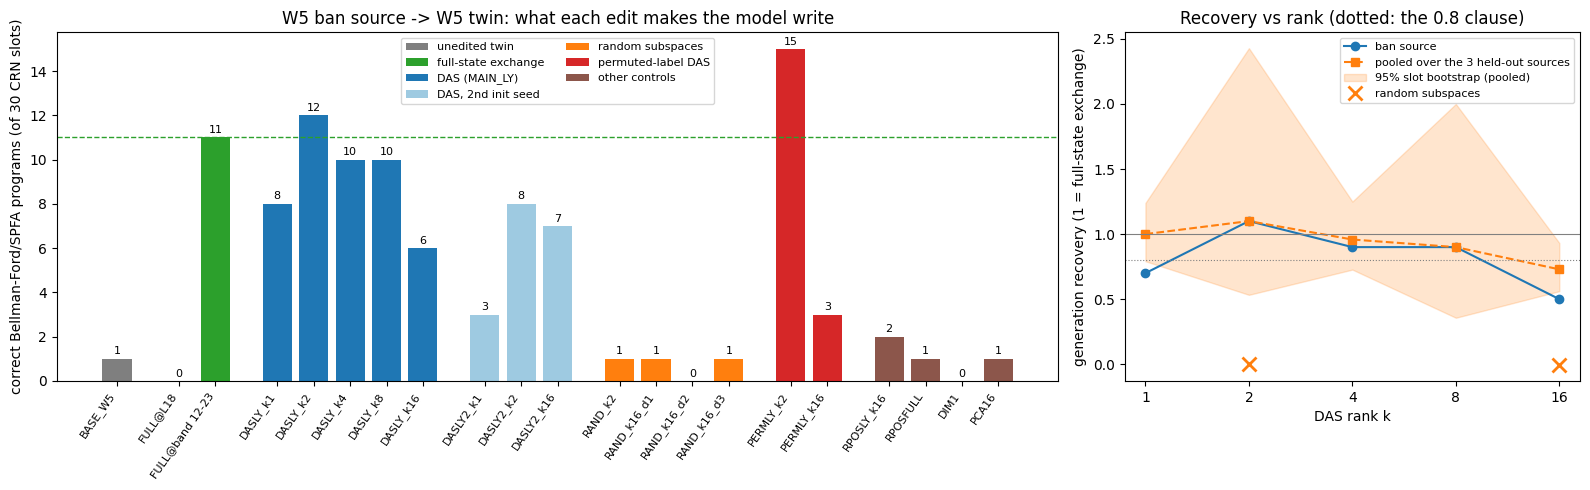

In [29]:
groups_ = [("unedited twin", ["BASE_W5"], "#7f7f7f"), ("full-state exchange", ["FULL_ban_L18", "FULL_ban_band"], "#2ca02c"),
           ("DAS (MAIN_LY)", [f"DASLY_ban_k{k}" for k in RANKS], "#1f77b4"),
           ("DAS, 2nd init seed", ["DASLY2_ban_k1", "DASLY2_ban_k2", "DASLY2_ban_k16"], "#9ecae1"),
           ("random subspaces", ["RAND_ban_k2", "RAND_ban_k16_d1", "RAND_ban_k16_d2", "RAND_ban_k16_d3"], "#ff7f0e"),
           ("permuted-label DAS", ["PERMLY_ban_k2", "PERMLY_ban_k16"], "#d62728"),
           ("other controls", ["RPOSLY_ban_k16", "RPOSFULL_ban", "DIM1_ban", "PCA16_ban"], "#8c564b")]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [2.2, 1]})
x, ticks, tlabels = 0.0, [], []
for name, arms_, col in groups_:
    for i, a in enumerate([a for a in arms_ if a in A_T2]):
        v = int(vec(A_T2, a, land).sum())
        ax.bar(x, v, color=col, label=name if i == 0 else None)
        ax.text(x, v + 0.2, str(v), ha="center", fontsize=8)
        ticks.append(x)
        tlabels.append(a.replace("FULL_ban_L18", "FULL@L18").replace("FULL_ban_band", "FULL@band 12-23").replace("_ban", ""))
        x += 1
    x += 0.7
ax.axhline(int(vec(A_T2, "FULL_ban_band", land).sum()), color="#2ca02c", ls="--", lw=1)
ax.set_xticks(ticks, tlabels, rotation=55, ha="right", fontsize=8)
ax.set_ylabel(f"correct Bellman-Ford/SPFA programs (of {N} CRN slots)")
ax.set_title("W5 ban source -> W5 twin: what each edit makes the model write")
ax.legend(fontsize=8, ncol=2)
nan = lambda v: np.nan if v is None else v
e_ = p1["tasks"]["T2"]
ax2.plot(RANKS, [nan(e_["per_source"]["ban"]["das"][k]["recovery"]) for k in RANKS], "o-", label="ban source")
ax2.plot(RANKS, [nan(e_["per_k"][k]["recovery"]) for k in RANKS], "s--", label="pooled over the 3 held-out sources")
ci_ = [e_["per_k"][k].get("recovery_ci") or [None, None] for k in RANKS]
ax2.fill_between(RANKS, [nan(c[0]) for c in ci_], [nan(c[1]) for c in ci_], color="C1", alpha=0.2,
                 label="95% slot bootstrap (pooled)")
for k in sorted({16, e_["k_star"]}):
    ax2.plot([k], [nan(e_["per_k"][k]["random_recovery"])], "x", color="#ff7f0e", ms=10, mew=2,
             label="random subspaces" if k == 16 else None)
ax2.axhline(1, color="gray", lw=0.8)
ax2.axhline(0.8, color="gray", ls=":", lw=0.8)
ax2.set_xscale("log", base=2)
ax2.set_xticks(RANKS, [str(k) for k in RANKS])
ax2.set_xlabel("DAS rank k")
ax2.set_ylabel("generation recovery (1 = full-state exchange)")
ax2.set_title("Recovery vs rank (dotted: the 0.8 clause)")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Figure 2: the causal manifold, in actual activation coordinates

The 151 T2 prompts are shown in the fitted map's own coordinates (`z = R_16 h`, block 18, averaged over the spec positions) and in two 2-D embeddings of the 16-d points: metric MDS and Isomap (geodesic distances on a kNN graph).
- Grey: the default paraphrases.
- Squares: the forced "Implement Y" prompts. Rings mark each algorithm's centroid, sized by how often the edits implemented it.
- Black X: the bans.
- Coloured markers: the novelty knobs.

The bans leave the default cloud (100th percentile of the null) and are displaced along the **Dijkstra -> Bellman-Ford axis, toward the runner-up**. Their coordinates along that axis are +1.1 to +1.8, against a null SD of 0.37; the forced-Dijkstra centroid sits at 1.1 and the Bellman-Ford one at 2.3 (printed under the figure). The 2-D views only approximate the 16-d distances, so read those numbers rather than the pictures alone.

The bans are not pushed to the far edge of the space or into an unseen region. Note also that in the DAS plane the twins (top left) sit apart from the forced prompts: the prompt's *form*, not only the algorithm it asks for, moves these coordinates.

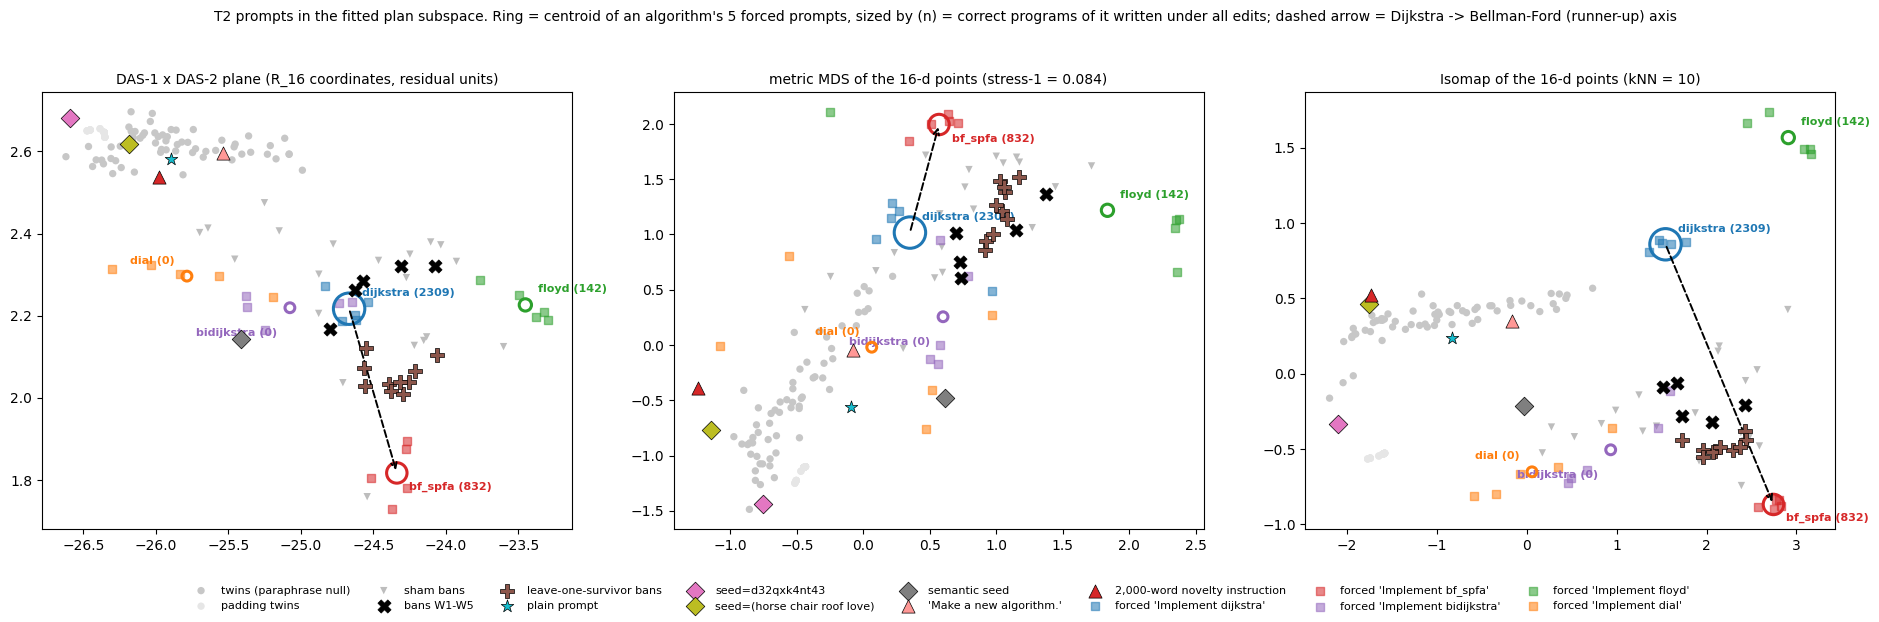

paraphrase null: {'n': 66, 'D_median': 0.522, 'D_95': 1.13, 'coord_sd': 0.37} | centroid coordinate along the runner-up axis: {'dijkstra': 1.13, 'bf_spfa': 2.3, 'bidijkstra': 0.95, 'floyd': 1.53, 'dial': 0.67}


In [30]:
co = m["coords"]
kinds = np.array(co["kind"])
Ys = np.array([y if y is not None else "" for y in co["Y"]])
alg_col = {"dijkstra": "#1f77b4", "bf_spfa": "#d62728", "bidijkstra": "#9467bd", "floyd": "#2ca02c", "dial": "#ff7f0e"}
cnt_k = m["implemented_counts"]["knobs"]  # correct programs per algorithm under every edit arm (+ exp29 directions)
style = {"twin": ("o", "#c7c7c7", "twins (paraphrase null)"), "padtwin": ("o", "#e6e6e6", "padding twins"),
         "shamban": ("v", "#bdbdbd", "sham bans"), "ban": ("X", "black", "bans W1-W5"),
         "multiban": ("P", "#8c564b", "leave-one-survivor bans"), "p0": ("*", "#17becf", "plain prompt"),
         "seed_rand1": ("D", "#e377c2", "seed=d32qxk4nt43"), "seed_rand2": ("D", "#bcbd22", "seed=(horse chair roof love)"),
         "seed_sem": ("D", "#7f7f7f", "semantic seed"), "instr_new": ("^", "#ff9896", "'Make a new algorithm.'"),
         "instr_novel": ("^", "#d62728", "2,000-word novelty instruction")}
bg = ("twin", "padtwin", "shamban")
fig, axes = plt.subplots(1, 3, figsize=(19, 6.2))
for ax, (emb, title) in zip(axes, [("das12", "DAS-1 x DAS-2 plane (R_16 coordinates, residual units)"),
                                   ("mds", f"metric MDS of the 16-d points (stress-1 = {m['mds_stress1']:.3f})"),
                                   ("isomap", f"Isomap of the 16-d points (kNN = {ISOMAP_NEIGHBORS})")]):
    P = np.array(co[emb])
    for kd, (mk, col, lab) in style.items():
        sel = kinds == kd
        if sel.any():
            ax.scatter(P[sel, 0], P[sel, 1], marker=mk, c=col, s=28 if kd in bg else 90, label=lab,
                       edgecolors="none" if kd in bg else "k", linewidths=0.5, zorder=1 if kd in bg else 4)
    cen = {}
    for Y, col in alg_col.items():
        sel = (kinds == "forced") & (Ys == Y)
        ax.scatter(P[sel, 0], P[sel, 1], marker="s", c=col, s=26, alpha=0.55, zorder=2,
                   label=f"forced 'Implement {Y}'" if emb == "das12" else None)
        cen[Y] = P[sel].mean(0)
        ax.scatter(*cen[Y], s=50 + 0.2 * cnt_k.get(Y, 0), facecolors="none", edgecolors=col, linewidths=2.2, zorder=3)
        off = {"dijkstra": (9, 9), "bf_spfa": (9, -12), "bidijkstra": (-9, -20), "floyd": (9, 9), "dial": (-9, 9)}[Y]
        ax.annotate(f"{Y} ({cnt_k.get(Y, 0)})", cen[Y], fontsize=8, color=col, fontweight="bold", xytext=off,
                    textcoords="offset points", ha="left" if off[0] > 0 else "right")
    ax.annotate("", xy=cen["bf_spfa"], xytext=cen["dijkstra"],
                arrowprops=dict(arrowstyle="->", color="black", lw=1.4, ls="--"))
    ax.set_title(title, fontsize=10)
h_, l_ = axes[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=8, fontsize=8, frameon=False)
fig.suptitle("T2 prompts in the fitted plan subspace. Ring = centroid of an algorithm's 5 forced prompts, sized by (n) = "
             "correct programs of it written under all edits; dashed arrow = Dijkstra -> Bellman-Ford (runner-up) axis",
             fontsize=10)
plt.tight_layout(rect=(0, 0.08, 1, 0.95))
plt.show()
print("paraphrase null:", {k: round(v, 3) if isinstance(v, float) else v for k, v in m["paraphrase_null"].items()},
      "| centroid coordinate along the runner-up axis:", {k: round(v, 2) for k, v in m["centroid_coord_along_runnerup"].items()})

### Figure 3: do random seeds or "be novel" instructions move the model?

- **Left:** the programs written under each novelty knob, on the same CRN slots, next to the rank-2 DAS edit.
- **Right:** where those prompts sit in the plan subspace. The x-axis is how far each prompt is from the cloud of default paraphrases (percentile of the null distance); the y-axis is how far it moves along the Dijkstra -> Bellman-Ford axis.

The bans sit at the 100th percentile, shifted toward Bellman-Ford. The seeds and short instructions stay inside the null, and the model keeps writing Dijkstra.

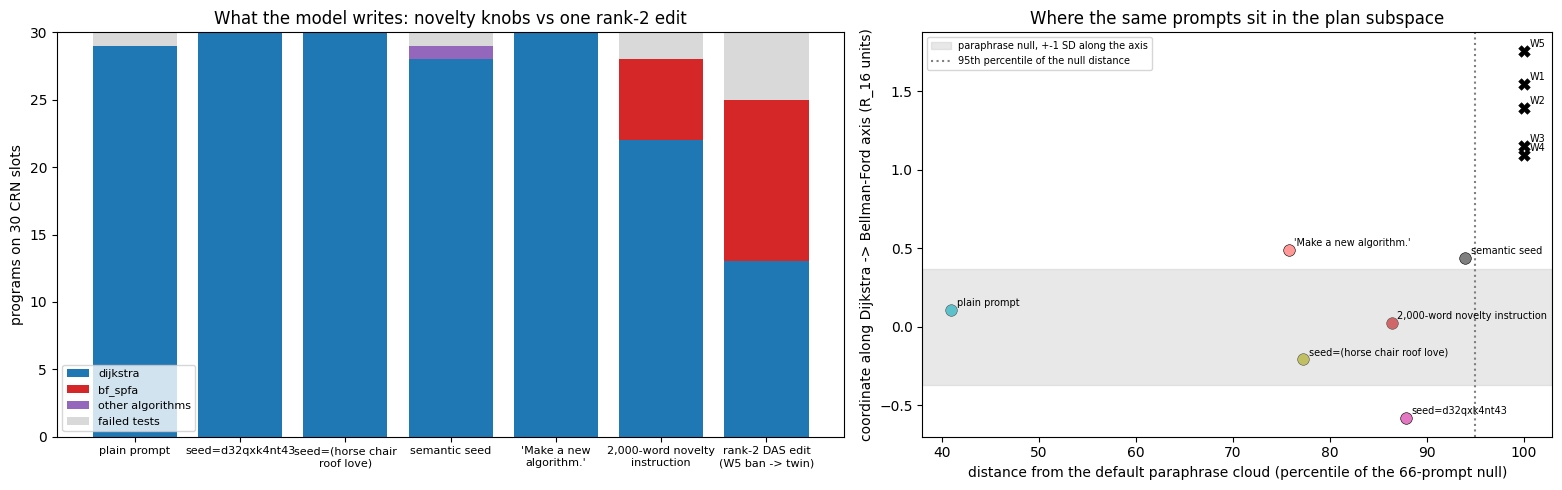

In [31]:
kinds_m = ["p0", "seed_rand1", "seed_rand2", "seed_sem", "instr_new", "instr_novel"]
names_m = {"p0": "plain prompt", "seed_rand1": "seed=d32qxk4nt43", "seed_rand2": "seed=(horse chair\nroof love)",
           "seed_sem": "semantic seed", "instr_new": "'Make a new\nalgorithm.'",
           "instr_novel": "2,000-word novelty\ninstruction", "das": "rank-2 DAS edit\n(W5 ban -> twin)"}
comp = {}
for kd in kinds_m:
    rs = [A_T2[f"MGEN_{kd}"][s] for s in range(N) if s in A_T2[f"MGEN_{kd}"]]
    comp[kd] = rs
comp["das"] = [A_T2["DASLY_ban_k2"][s] for s in range(N) if s in A_T2["DASLY_ban_k2"]]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1.25, 1]})
bottom = np.zeros(len(comp))
for lab, col in zip(["dijkstra", "bf_spfa", "other algorithms", "failed tests"], ["#1f77b4", "#d62728", "#9467bd", "#d9d9d9"]):
    vals = np.array([sum(1 for r in rs if (not r["passed"]) if lab == "failed tests") if lab == "failed tests" else
                     sum(1 for r in rs if r["passed"] and (r["label"] == lab if lab in ("dijkstra", "bf_spfa")
                                                           else r["label"] not in ("dijkstra", "bf_spfa")))
                     for rs in comp.values()])
    ax.bar(range(len(comp)), vals, bottom=bottom, color=col, label=lab)
    bottom += vals
ax.set_xticks(range(len(comp)), [names_m[k] for k in comp], fontsize=8)
ax.set_ylabel(f"programs on {N} CRN slots")
ax.set_title("What the model writes: novelty knobs vs one rank-2 edit")
ax.legend(fontsize=8)
# placement of the same prompts in R_16 (distance from the default paraphrase cloud vs the runner-up axis)
pr = m["probes"]
pcol = {"ban": "black", "p0": "#17becf", "seed_rand1": "#e377c2", "seed_rand2": "#bcbd22", "seed_sem": "#7f7f7f",
        "instr_new": "#ff9896", "instr_novel": "#d62728"}
for k_, e in pr.items():
    ax2.scatter(e["null_percentile"], e["coord_along_runnerup"], c=pcol.get(e["kind"], "gray"), s=70,
                marker="X" if e["kind"] == "ban" else "o", edgecolors="k", linewidths=0.4)
    lab = k_.split("|")[2] if e["kind"] == "ban" else names_m.get(e["kind"], e["kind"]).replace("\n", " ")
    ax2.annotate(lab, (e["null_percentile"], e["coord_along_runnerup"]), fontsize=7, xytext=(4, 3),
                 textcoords="offset points")
sd = m["paraphrase_null"]["coord_sd"]
ax2.axhspan(-sd, sd, color="#c7c7c7", alpha=0.4, label="paraphrase null, +-1 SD along the axis")
ax2.axvline(95, color="gray", ls=":", label="95th percentile of the null distance")
ax2.set_xlabel("distance from the default paraphrase cloud (percentile of the 66-prompt null)")
ax2.set_ylabel("coordinate along Dijkstra -> Bellman-Ford axis (R_16 units)")
ax2.set_title("Where the same prompts sit in the plan subspace")
ax2.legend(fontsize=7, loc="upper left")
plt.tight_layout()
plt.show()

### Figure 4: routing (C) of the forced sources

What the edited padding twin writes when the source is a forced *"Implement Y"* prompt.
- **Floyd-Warshall (right).** The full-state exchange mostly lands on Bellman-Ford (8 Floyd-Warshall of 20 correct). The rank-1 DAS edit writes Floyd-Warshall on every correct program (28/28). The map writes this algorithm *more* strongly than the source's own states carry it.
- **Bellman-Ford (left).** The full-state exchange carries it completely (30/30). DAS carries it only partly (13/30 at rank 1), and less at higher rank.

Together with the permuted-label result, this is why the subspace reads as a steering handle that can *write* an algorithm, not as a variable that faithfully *carries* the prompt's choice.

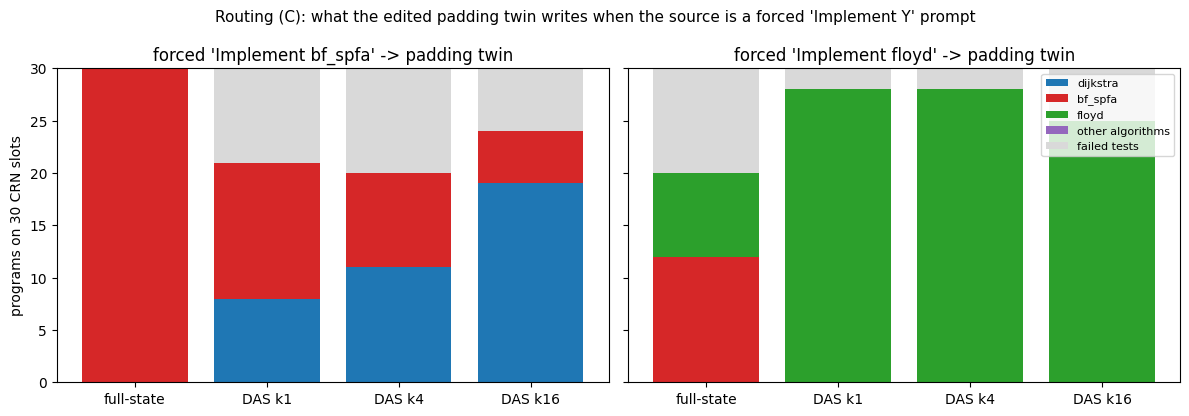

In [32]:
labs4 = ["dijkstra", "bf_spfa", "floyd", "other algorithms", "failed tests"]
col4 = ["#1f77b4", "#d62728", "#2ca02c", "#9467bd", "#d9d9d9"]
fig, axes = plt.subplots(1, len(rt["T2"]["per_Y"]), figsize=(12, 4.2), sharey=True)
for ax, Y in zip(np.atleast_1d(axes), rt["T2"]["per_Y"]):
    arms_ = [nm for nm in ("full", "k1", "k4", "k16") if Y in rt["T2"]["confusion"].get(nm, {})]
    bottom = np.zeros(len(arms_))
    for lab, col in zip(labs4, col4):
        vals = []
        for nm in arms_:
            cf = rt["T2"]["confusion"][nm][Y]
            vals.append(cf["fail"] if lab == "failed tests" else
                        sum(v for l, v in cf.items() if l not in ("dijkstra", "bf_spfa", "floyd", "fail"))
                        if lab == "other algorithms" else cf.get(lab, 0))
        ax.bar(arms_, vals, bottom=bottom, color=col, label=lab)
        bottom += np.array(vals)
    ax.set_xticks(range(len(arms_)), ["full-state" if a == "full" else f"DAS {a}" for a in arms_])
    ax.set_title(f"forced 'Implement {Y}' -> padding twin")
axes[0].set_ylabel(f"programs on {N} CRN slots")
axes[-1].legend(fontsize=8, loc="upper right")
fig.suptitle("Routing (C): what the edited padding twin writes when the source is a forced 'Implement Y' prompt", fontsize=11)
plt.tight_layout()
plt.show()

## Conclusions

**Is there an "algorithm switch" inside Qwen3-8B?** There is a strong, low-rank handle on the choice:
- a rank-2 edit of mid-layer task-spec states moves the twin from Dijkstra to Bellman-Ford as often as exchanging the full states does (12 vs 11 of 30);
- it routes a forced Floyd-Warshall prompt better than the full states do (28/28 vs 8/20);
- random subspaces of the same rank do nothing.

It is **not** a clean causal variable:
- a map fitted with permuted labels steers just as well (15/30);
- a randomly initialised network admits an equally good teacher-forced fit;
- the lambda sweep is graded, so the edit sets a probability over algorithms rather than flipping a switch.

P1 therefore fails, and the hypothesis is NOT SUPPORTED.

**Does context help the model leave its "mean answer"?** In the map's coordinates, every ban leaves the cloud of default paraphrases, and it moves along the Dijkstra -> Bellman-Ford axis, toward the model's runner-up. The novelty knobs stay *inside* the default cloud: random seeds, a semantic seed and "Make a new algorithm.". The behaviour agrees: they keep Dijkstra on 28-30 of 30 slots. Only the 2,000-word novelty instruction moves anything (6/30 Bellman-Ford), and it moves during the written rationale, not in the prompt states. Prohibiting the other four algorithms does not place a prompt near the survivor. Across all edits, no correct "other" program was novel.

In plain terms: bans and steering move the model **to the next most likely textbook algorithm**. They do not move it to the edge of the space, and nothing here made it invent a new algorithm.

**Scaling back up.** `N_SLOTS = 30`, `BOOT_REPS = 2000`, `MDS_N_INIT = 4`, `GEODESIC_KS = (5, 10, 15)` and `LOS_NULL_REPS = 1000` are the original analysis settings, and they run in seconds on the demo rows. Re-running the GPU stages needs the full experiment folder and `RUN_FULL_PIPELINE = True` on a >= 24 GB GPU (about 1.6 GPU-hours for 4,500 programs, about 3 h overall).